# Imports

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import RFE, SelectKBest, VarianceThreshold, f_classif, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score, classification_report, f1_score
from sklearn.model_selection import GridSearchCV, ParameterGrid, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC

### Reusable evaluation functions

In [2]:
# Shared reporting helpers: these do not fit or modify any model.
SUBTYPE_NAMES = ["Basal", "HER2", "LumA", "LumB"]

def evaluate_predictions(y_true, y_pred, report=True):
    """Print consistent classification metrics; return a one-row summary dict."""
    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, average="macro"),
    }
    for name, value in metrics.items():
        print(f"{name}: {value:.4f}")
    if report:
        print(classification_report(
            y_true, y_pred, labels=[0, 1, 2, 3],
            target_names=SUBTYPE_NAMES, zero_division=0
        ))
    return metrics

def plot_confusion(y_true, y_pred, title):
    """Display a consistent four-subtype confusion matrix."""
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, labels=[0, 1, 2, 3],
        display_labels=SUBTYPE_NAMES, cmap="Blues"
    )
    plt.title(title)
    plt.show()

def compare_predictions(predictions, y_true):
    """Summarise predictions from multiple already-fitted models."""
    return pd.DataFrame({
        name: {
            "Accuracy": accuracy_score(y_true, pred),
            "Balanced Accuracy": balanced_accuracy_score(y_true, pred),
            "Macro F1": f1_score(y_true, pred, average="macro")
        }
        for name, pred in predictions.items()
    }).T


# Stage 1 — Data loading, integrity checks and dataset understanding

## Loading Datasets

In [4]:
train_path = "/Users/alfadhul/Downloads/03_Machine_Learning/Capstone/moanna_data/training/moanna_training_data.tsv"
train_labels_path = "/Users/alfadhul/Downloads/03_Machine_Learning/Capstone/moanna_data/training/moanna_training_label.tsv"
train = pd.read_csv(train_path, sep="\t")
train_labels = pd.read_csv(train_labels_path, sep="\t")

In [5]:
validation_path = "/Users/alfadhul/Downloads/03_Machine_Learning/Capstone/moanna_data/training/moanna_validation_data.tsv"
validation_label_path = "/Users/alfadhul/Downloads/03_Machine_Learning/Capstone/moanna_data/training/moanna_validation_label.tsv"
validation = pd.read_csv(validation_path, sep="\t")
validation_labels = pd.read_csv(validation_label_path, sep="\t")

In [2]:
test_path = "/Users/alfadhul/Downloads/03_Machine_Learning/Capstone/moanna_data/testing/moanna_testing_data.tsv"
test_label_path = "/Users/alfadhul/Downloads/03_Machine_Learning/Capstone/moanna_data/testing/moanna_testing_label.tsv"
test = pd.read_csv(test_path, sep="\t")
test_labels = pd.read_csv(test_label_path, sep="\t")

## Exploring the data

In [7]:
datasets = {
    "Training data": train,
    "Training labels": train_labels,
    "Validation data": validation,
    "Validation labels": validation_labels,
    "Testing data": test,
    "Testing labels": test_labels
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Training data: (1182, 46777)
Training labels: (1182, 7)
Validation data: (507, 46777)
Validation labels: (507, 7)
Testing data: (631, 46777)
Testing labels: (631, 7)


In [8]:
for name, df in datasets.items():
    print(f"\n{'='*50}")
    print(name)
    print("First 10 columns:", df.columns[:10].tolist())
    print("Last 5 columns:", df.columns[-5:].tolist())
    print("\nData types:")
    print(df.dtypes.value_counts())


Training data
First 10 columns: ['Unnamed: 0', 'A1BG_EXPR', 'A1CF_EXPR', 'A2M_EXPR', 'A4GALT_EXPR', 'A4GNT_EXPR', 'AAAS_EXPR', 'AACS_EXPR', 'AADACL2_EXPR', 'AADACL3_EXPR']
Last 5 columns: ['ZYG11A_SNP', 'ZYG11B_SNP', 'ZYX_SNP', 'ZZEF1_SNP', 'ZZZ3_SNP']

Data types:
float64    46776
str            1
Name: count, dtype: int64

Training labels
First 10 columns: ['Unnamed: 0', 'ERStatus', 'HER2Status', 'Pam50Subtype', 'Pam50SubtypeSingleLuminal', 'BasalNonBasal', 'Luminal']
Last 5 columns: ['HER2Status', 'Pam50Subtype', 'Pam50SubtypeSingleLuminal', 'BasalNonBasal', 'Luminal']

Data types:
int64    6
str      1
Name: count, dtype: int64

Validation data
First 10 columns: ['Unnamed: 0', 'A1BG_EXPR', 'A1CF_EXPR', 'A2M_EXPR', 'A4GALT_EXPR', 'A4GNT_EXPR', 'AAAS_EXPR', 'AACS_EXPR', 'AADACL2_EXPR', 'AADACL3_EXPR']
Last 5 columns: ['ZYG11A_SNP', 'ZYG11B_SNP', 'ZYX_SNP', 'ZZEF1_SNP', 'ZZZ3_SNP']

Data types:
float64    46776
str            1
Name: count, dtype: int64

Validation labels
First 10 co

## Checking Sample ids, Matching data and labels, Checking for ovelap in data

In [9]:
for name, df in datasets.items():
    print(f"\n{name}")
    print(df.columns[0])
    print(df.iloc[:5, 0].tolist())


Training data
Unnamed: 0
['MB-6098', 'MB-5420', 'MB-4763', 'MB-4873', 'MB-0639']

Training labels
Unnamed: 0
['MB-6098', 'MB-5420', 'MB-4763', 'MB-4873', 'MB-0639']

Validation data
Unnamed: 0
['MB-2797', 'MB-4769', 'MB-5233', 'MB-0120', 'MB-3049']

Validation labels
Unnamed: 0
['MB-2797', 'MB-4769', 'MB-5233', 'MB-0120', 'MB-3049']

Testing data
Unnamed: 0
['TCGA-A2-A0D4-01', 'TCGA-BH-A0BD-01', 'TCGA-D8-A4Z1-01', 'TCGA-BH-A0DP-01', 'TCGA-A8-A091-01']

Testing labels
Unnamed: 0
['TCGA-A2-A0D4-01', 'TCGA-BH-A0BD-01', 'TCGA-D8-A4Z1-01', 'TCGA-BH-A0DP-01', 'TCGA-A8-A091-01']


In [10]:
id_columns = {
    "Training data": train["Unnamed: 0"],
    "Training labels": train_labels["Unnamed: 0"],
    "Validation data": validation["Unnamed: 0"],
    "Validation labels": validation_labels["Unnamed: 0"],
    "Testing data": test["Unnamed: 0"],
    "Testing labels": test_labels["Unnamed: 0"]
}

for name, ids in id_columns.items():
    print(f"\n{name}")
    print("Missing IDs:", ids.isna().sum())
    print("Duplicate IDs:", ids.duplicated().sum())


Training data
Missing IDs: 0
Duplicate IDs: 0

Training labels
Missing IDs: 0
Duplicate IDs: 0

Validation data
Missing IDs: 0
Duplicate IDs: 0

Validation labels
Missing IDs: 0
Duplicate IDs: 0

Testing data
Missing IDs: 0
Duplicate IDs: 0

Testing labels
Missing IDs: 0
Duplicate IDs: 0


In [11]:
partitions = {
    "Training": (train, train_labels),
    "Validation": (validation, validation_labels),
    "Testing": (test, test_labels)
}

for name, (data, labels) in partitions.items():
    print(f"\n{name}")
    print("Same IDs:", data["Unnamed: 0"].equals(labels["Unnamed: 0"]))
    print("Same number of samples:", len(data) == len(labels))


Training
Same IDs: True
Same number of samples: True

Validation
Same IDs: True
Same number of samples: True

Testing
Same IDs: True
Same number of samples: True


In [12]:
train_ids = set(train["Unnamed: 0"])
val_ids = set(validation["Unnamed: 0"])
test_ids = set(test["Unnamed: 0"])

print("Training ∩ Validation:", len(train_ids & val_ids))
print("Training ∩ Testing:", len(train_ids & test_ids))
print("Validation ∩ Testing:", len(val_ids & test_ids))

Training ∩ Validation: 0
Training ∩ Testing: 0
Validation ∩ Testing: 0


In [13]:
for name, (data, labels) in partitions.items():
    data_ids = set(data["Unnamed: 0"])
    label_ids = set(labels["Unnamed: 0"])

    print(f"\n{name}")
    print("IDs only in data:", len(data_ids - label_ids))
    print("IDs only in labels:", len(label_ids - data_ids))


Training
IDs only in data: 0
IDs only in labels: 0

Validation
IDs only in data: 0
IDs only in labels: 0

Testing
IDs only in data: 0
IDs only in labels: 0


## Separating Molecular Layers, Checking Features

In [14]:
# Remove sample ID
feature_columns = train.columns.drop("Unnamed: 0")

# Separate molecular layers
expr_features = [col for col in feature_columns if col.endswith("_EXPR")]
cnv_features = [col for col in feature_columns if col.endswith("_CNV")]
snp_features = [col for col in feature_columns if col.endswith("_SNP")]

print("EXPR features:", len(expr_features))
print("CNV features:", len(cnv_features))
print("SNP features:", len(snp_features))
print("Total features:", len(feature_columns))

EXPR features: 15592
CNV features: 15592
SNP features: 15592
Total features: 46776


In [15]:
print("Duplicate feature names:",
      train.columns.drop("Unnamed: 0").duplicated().sum())

Duplicate feature names: 0


In [16]:
print("EXPR examples:", expr_features[:5])
print("CNV examples:", cnv_features[:5])
print("SNP examples:", snp_features[:5])

EXPR examples: ['A1BG_EXPR', 'A1CF_EXPR', 'A2M_EXPR', 'A4GALT_EXPR', 'A4GNT_EXPR']
CNV examples: ['A1BG_CNV', 'A1CF_CNV', 'A2M_CNV', 'A4GALT_CNV', 'A4GNT_CNV']
SNP examples: ['A1BG_SNP', 'A1CF_SNP', 'A2M_SNP', 'A4GALT_SNP', 'A4GNT_SNP']


## Checking for Pam50 genes

In [17]:
pam50_genes = [
    "ACTR3B", "ANLN", "BAG1", "BCL2", "BIRC5",
    "BLVRA", "CCNB1", "CCNE1", "CDC20", "CDC6",
    "NUF2", "CDH3", "CENPF", "CEP55", "CXXC5",
    "EGFR", "ERBB2", "ESR1", "EXO1", "FGFR4",
    "FOXA1", "FOXC1", "GPR160", "GRB7", "KIF2C",
    "NDC80", "KRT14", "KRT17", "KRT5", "MAPT",
    "MDM2", "MELK", "MIA", "MKI67", "MLPH",
    "MMP11", "MYBL2", "MYC", "NAT1", "ORC6",
    "PGR", "PHGDH", "PTTG1", "RRM2", "SFRP1",
    "SLC39A6", "TMEM45B", "TYMS", "UBE2C", "UBE2T"
]

print("Number of PAM50 reference genes:", len(pam50_genes))
print("Unique PAM50 genes:", len(set(pam50_genes)))

Number of PAM50 reference genes: 50
Unique PAM50 genes: 50


In [18]:
expr_genes = {col.removesuffix("_EXPR") for col in expr_features}
cnv_genes = {col.removesuffix("_CNV") for col in cnv_features}
snp_genes = {col.removesuffix("_SNP") for col in snp_features}

modalities = {
    "EXPR": expr_genes,
    "CNV": cnv_genes,
    "SNP": snp_genes
}

In [19]:
for modality, genes in modalities.items():

    present = set(pam50_genes) & genes
    absent = set(pam50_genes) - genes

    print(f"\n{modality}")
    print("PAM50 genes present:", len(present))
    print("PAM50 genes absent:", len(absent))
    print("Present:", sorted(present))
    print("Absent:", sorted(absent))


EXPR
PAM50 genes present: 45
PAM50 genes absent: 5
Present: ['ACTR3B', 'ANLN', 'BCL2', 'BIRC5', 'BLVRA', 'CCNB1', 'CCNE1', 'CDC20', 'CDC6', 'CDH3', 'CENPF', 'CEP55', 'CXXC5', 'EGFR', 'ERBB2', 'ESR1', 'EXO1', 'FGFR4', 'FOXA1', 'FOXC1', 'GRB7', 'KIF2C', 'KRT14', 'KRT17', 'KRT5', 'MAPT', 'MDM2', 'MELK', 'MKI67', 'MLPH', 'MMP11', 'MYBL2', 'MYC', 'NAT1', 'NDC80', 'NUF2', 'PGR', 'PHGDH', 'PTTG1', 'RRM2', 'SFRP1', 'SLC39A6', 'TYMS', 'UBE2C', 'UBE2T']
Absent: ['BAG1', 'GPR160', 'MIA', 'ORC6', 'TMEM45B']

CNV
PAM50 genes present: 45
PAM50 genes absent: 5
Present: ['ACTR3B', 'ANLN', 'BCL2', 'BIRC5', 'BLVRA', 'CCNB1', 'CCNE1', 'CDC20', 'CDC6', 'CDH3', 'CENPF', 'CEP55', 'CXXC5', 'EGFR', 'ERBB2', 'ESR1', 'EXO1', 'FGFR4', 'FOXA1', 'FOXC1', 'GRB7', 'KIF2C', 'KRT14', 'KRT17', 'KRT5', 'MAPT', 'MDM2', 'MELK', 'MKI67', 'MLPH', 'MMP11', 'MYBL2', 'MYC', 'NAT1', 'NDC80', 'NUF2', 'PGR', 'PHGDH', 'PTTG1', 'RRM2', 'SFRP1', 'SLC39A6', 'TYMS', 'UBE2C', 'UBE2T']
Absent: ['BAG1', 'GPR160', 'MIA', 'ORC6', 'TMEM45B

In [20]:
print("EXPR vs CNV:", expr_genes == cnv_genes)
print("EXPR vs SNP:", expr_genes == snp_genes)
print("CNV vs SNP:", cnv_genes == snp_genes)

EXPR vs CNV: True
EXPR vs SNP: True
CNV vs SNP: True


## Data Quality (Missing Values, Duplicates)

In [21]:
cohorts = {
    "Training": train,
    "Validation": validation,
    "Testing": test
}

for name, df in cohorts.items():
    print(f"\n{name}")
    print("Missing values:", df.isna().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())
    print("Duplicate columns:", df.columns.duplicated().sum())


Training
Missing values: 0
Duplicate rows: 0
Duplicate columns: 0

Validation
Missing values: 0
Duplicate rows: 0
Duplicate columns: 0

Testing
Missing values: 0
Duplicate rows: 0
Duplicate columns: 0


In [22]:
modalities = {
    "EXPR": expr_features,
    "CNV": cnv_features,
    "SNP": snp_features
}
for name, df in cohorts.items():
    print(f"\n{name}")

    for modality, features in modalities.items():
        X = df[features]

        constant = (X.nunique() == 1).sum()

        print(modality, ":", constant)


Training
EXPR : 0
CNV : 0
SNP : 15429

Validation
EXPR : 0
CNV : 0
SNP : 15430

Testing
EXPR : 13
CNV : 0
SNP : 1397


In [23]:
for cohort, df in cohorts.items():
    X = df[snp_features]

    print(cohort)
    print("Variable SNP:", (X.nunique() > 1).sum())
    print("Constant SNP:", (X.nunique() == 1).sum())

Training
Variable SNP: 163
Constant SNP: 15429
Validation
Variable SNP: 162
Constant SNP: 15430
Testing
Variable SNP: 14195
Constant SNP: 1397


In [24]:
X = test[expr_features]

constant = X.columns[X.nunique() == 1]

print("Constant expression features:")
print(constant.tolist())

print("\nTheir values:")
print(X[constant].iloc[0])

Constant expression features:
['CT47A6_EXPR', 'CT47A7_EXPR', 'HSFX1_EXPR', 'KRTAP19-2_EXPR', 'KRTAP25-1_EXPR', 'KRTAP6-1_EXPR', 'LCE4A_EXPR', 'NMS_EXPR', 'OR2T29_EXPR', 'OR2Y1_EXPR', 'OR5H14_EXPR', 'OR5R1_EXPR', 'TAAR2_EXPR']

Their values:
CT47A6_EXPR      -0.031718
CT47A7_EXPR      -0.031718
HSFX1_EXPR       -0.031718
KRTAP19-2_EXPR   -0.031718
KRTAP25-1_EXPR   -0.031718
KRTAP6-1_EXPR    -0.031718
LCE4A_EXPR       -0.033819
NMS_EXPR         -0.031718
OR2T29_EXPR      -0.031718
OR2Y1_EXPR       -0.051127
OR5H14_EXPR      -0.041569
OR5R1_EXPR       -0.049753
TAAR2_EXPR       -0.045897
Name: 0, dtype: float64


## Exploring Labels

In [25]:
label_cohorts = {
    "Training": train_labels,
    "Validation": validation_labels,
    "Testing": test_labels
}

for name, df in label_cohorts.items():
    y = df["Pam50Subtype"]

    print(f"\n{name}")
    print("Missing labels:", y.isna().sum())
    print("Unique labels:", y.unique())


Training
Missing labels: 0
Unique labels: [0 1 3 2]

Validation
Missing labels: 0
Unique labels: [2 0 3 1]

Testing
Missing labels: 0
Unique labels: [3 2 1 0]


In [26]:
for name, df in label_cohorts.items():
    y = df["Pam50Subtype"]

    distribution = pd.DataFrame({
        "Count": y.value_counts(),
        "Percentage": (y.value_counts(normalize=True) * 100).round(2)
    }).sort_index()

    print(f"\n{name}")
    print(distribution)


Training
              Count  Percentage
Pam50Subtype                   
0               213       18.02
1               151       12.77
2               485       41.03
3               333       28.17

Validation
              Count  Percentage
Pam50Subtype                   
0                89       17.55
1                82       16.17
2               202       39.84
3               134       26.43

Testing
              Count  Percentage
Pam50Subtype                   
0               112       17.75
1                59        9.35
2               333       52.77
3               127       20.13


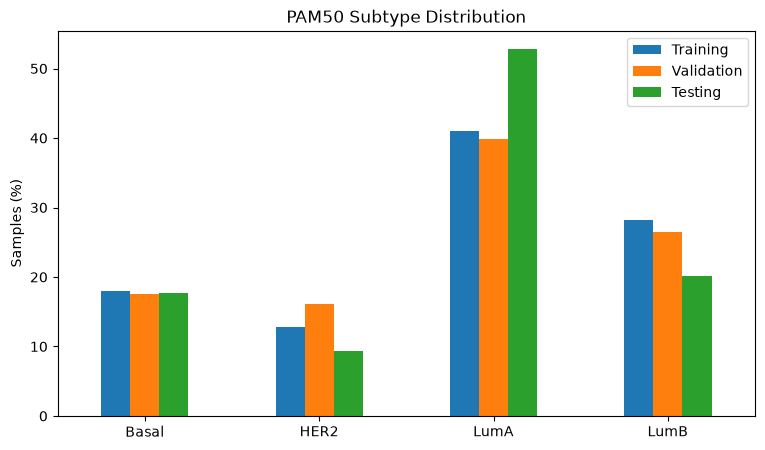

In [27]:
distribution = pd.DataFrame({
    "Training": train_labels["Pam50Subtype"].value_counts(normalize=True) * 100,
    "Validation": validation_labels["Pam50Subtype"].value_counts(normalize=True) * 100,
    "Testing": test_labels["Pam50Subtype"].value_counts(normalize=True) * 100
}).sort_index()

distribution.index = ["Basal", "HER2", "LumA", "LumB"]

distribution.plot(kind="bar", figsize=(9, 5))

plt.title("PAM50 Subtype Distribution")
plt.ylabel("Samples (%)")
plt.xticks(rotation=0)
plt.show()

## Descriptive Statistics of Features

In [28]:
for name, df in cohorts.items():
    print(f"\n{name} - Gene Expression")

    X = df[expr_features]

    print(X.stack().describe().round(2))


Training - Gene Expression
count    18429744.00
mean            0.00
std             1.00
min            -9.36
25%            -0.64
50%            -0.08
75%             0.57
max            32.21
dtype: float64

Validation - Gene Expression
count    7905144.00
mean           0.00
std            1.01
min          -10.45
25%           -0.65
50%           -0.08
75%            0.57
max           31.73
dtype: float64

Testing - Gene Expression
count    9838552.00
mean          -0.00
std            0.98
min           -3.40
25%           -0.46
50%           -0.16
75%            0.18
max           31.50
dtype: float64


In [29]:
for name, df in cohorts.items():
    print(f"\n{name} - CNV")

    X = df[cnv_features]

    print(X.stack().value_counts().sort_index())


Training - CNV
-2.0       14222
-1.0     2973731
 0.0    13170044
 1.0     1707311
 2.0      564436
Name: count, dtype: int64

Validation - CNV
-2.0       5557
-1.0    1385680
 0.0    5528232
 1.0     741408
 2.0     244267
Name: count, dtype: int64

Testing - CNV
-2.0      30992
-1.0    2302430
 0.0    5217069
 1.0    2121188
 2.0     166873
Name: count, dtype: int64


In [30]:
for name, df in cohorts.items():
    print(f"\n{name} - SNP")

    X = df[snp_features]

    mutation_frequency = X.mean() * 100

    print(mutation_frequency.nlargest(10).round(2))


Training - SNP
PIK3CA_SNP    43.32
TP53_SNP      35.28
MUC16_SNP     25.55
AHNAK2_SNP    23.43
SYNE1_SNP     17.51
GATA3_SNP     13.79
AHNAK_SNP     12.35
MAP3K1_SNP    12.01
DNAH2_SNP     11.34
HERC2_SNP     10.49
dtype: float64

Validation - SNP
TP53_SNP      41.22
PIK3CA_SNP    39.05
AHNAK2_SNP    21.70
MUC16_SNP     18.93
SYNE1_SNP     16.77
GATA3_SNP     13.41
HERC2_SNP     13.02
MAP3K1_SNP    12.03
DNAH2_SNP     11.64
AHNAK_SNP     10.85
dtype: float64

Testing - SNP
TP53_SNP      37.56
PIK3CA_SNP    36.61
TTN_SNP       22.82
MUC16_SNP     15.85
CDH1_SNP      13.63
GATA3_SNP     12.36
MAP3K1_SNP    10.78
SYNE1_SNP      9.98
RYR2_SNP       9.51
FLG_SNP        8.72
dtype: float64


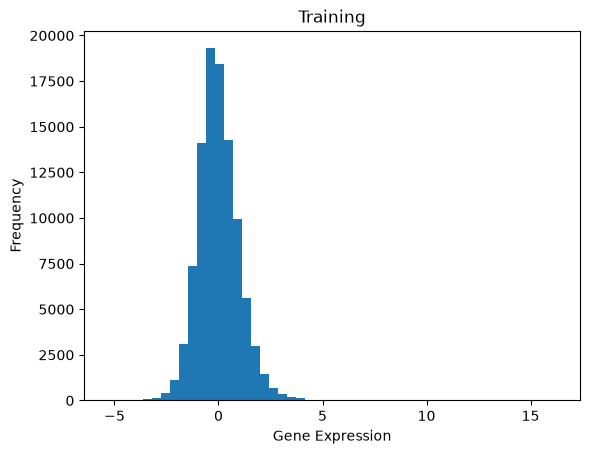

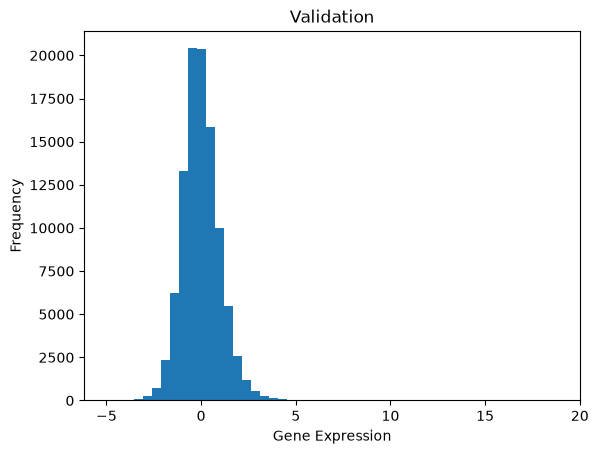

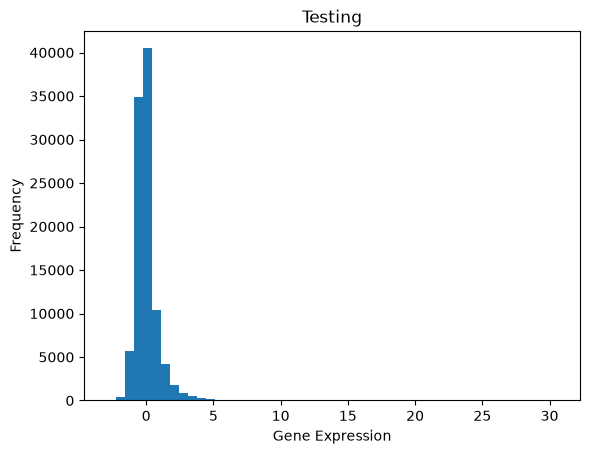

In [31]:
for name, df in cohorts.items():
    X = df[expr_features]

    plt.hist(X.stack().sample(100000, random_state=42), bins=50)
    plt.title(name)
    plt.xlabel("Gene Expression")
    plt.ylabel("Frequency")
    plt.show()

## Differences between METABRIC and TCGA

In [32]:
expr_difference = (
    train[expr_features].mean() - test[expr_features].mean()
).abs()

print(expr_difference.describe().round(4))
print(expr_difference.nlargest(10).round(4))

count    15592.0000
mean         0.0366
std          0.0274
min          0.0000
25%          0.0149
50%          0.0309
75%          0.0529
max          0.1610
dtype: float64
TMCO6_EXPR       0.1610
CDK5_EXPR        0.1602
SLC25A39_EXPR    0.1597
LSM12_EXPR       0.1568
NEDD8_EXPR       0.1568
DNAJC7_EXPR      0.1565
RELN_EXPR        0.1547
KAT2A_EXPR       0.1544
LRRC61_EXPR      0.1518
ANTXR2_EXPR      0.1513
dtype: float64


In [33]:
cnv_difference = (
    (train[cnv_features] != 0).mean() -
    (test[cnv_features] != 0).mean()
).abs() * 100

print(cnv_difference.describe().round(2))
print(cnv_difference.nlargest(10).round(2))

count    15592.00
mean        18.43
std          3.88
min          1.96
25%         16.21
50%         18.91
75%         20.91
max         50.49
dtype: float64
NOTCH2_CNV     50.49
FCGR1B_CNV     49.47
NAA38_CNV      42.13
ZNF267_CNV     32.11
UBE2MP1_CNV    31.10
DDAH1_CNV      28.63
KCNA2_CNV      27.50
NHLH2_CNV      27.46
CD58_CNV       27.31
CHMP4B_CNV     27.31
dtype: float64


In [34]:
train_snp = train[snp_features]
test_snp = test[snp_features]

train_genes = set(train_snp.columns[train_snp.nunique() > 1])
test_genes = set(test_snp.columns[test_snp.nunique() > 1])

print("Training:", len(train_genes))
print("Testing:", len(test_genes))
print("Shared:", len(train_genes & test_genes))
print("Training only:", len(train_genes - test_genes))
print("Testing only:", len(test_genes - train_genes))

Training: 163
Testing: 14195
Shared: 161
Training only: 2
Testing only: 14034


# Stage 2 - Data Preparation

In [6]:
X_train = train.drop(columns=["Unnamed: 0"])
X_val = validation.drop(columns=["Unnamed: 0"])
X_test = test.drop(columns=["Unnamed: 0"])

y_train = train_labels["Pam50Subtype"]
y_val = validation_labels["Pam50Subtype"]
y_test = test_labels["Pam50Subtype"]

In [37]:
# Training
X_train_expr = X_train[expr_features]
X_train_cnv = X_train[cnv_features]
X_train_snp = X_train[snp_features]

# Validation
X_val_expr = X_val[expr_features]
X_val_cnv = X_val[cnv_features]
X_val_snp = X_val[snp_features]

# Testing
X_test_expr = X_test[expr_features]
X_test_cnv = X_test[cnv_features]
X_test_snp = X_test[snp_features]

In [38]:
print("EXPR:", X_train_expr.shape, X_val_expr.shape, X_test_expr.shape)
print("CNV:", X_train_cnv.shape, X_val_cnv.shape, X_test_cnv.shape)
print("SNP:", X_train_snp.shape, X_val_snp.shape, X_test_snp.shape)

EXPR: (1182, 15592) (507, 15592) (631, 15592)
CNV: (1182, 15592) (507, 15592) (631, 15592)
SNP: (1182, 15592) (507, 15592) (631, 15592)


# Stage 3 - EDA

## Expression

In [39]:
# Selected genes
selected_genes = [
    "ESR1_EXPR",
    "PGR_EXPR",
    "ERBB2_EXPR",
    "MKI67_EXPR",
    "FOXC1_EXPR"]

# Molecular subtype labels
class_names = {
    0: "Basal",
    1: "HER2",
    2: "LumA",
    3: "LumB"}

# Gene expression data
X = X_train_expr[selected_genes].copy()

# Add molecular subtypes
X["Subtype"] = y_train.map(class_names)

print(X.head())

   ESR1_EXPR  PGR_EXPR  ERBB2_EXPR  MKI67_EXPR  FOXC1_EXPR Subtype
0  -1.632637 -1.163327   -0.790206    0.662278    2.691969   Basal
1  -0.467876 -0.596637    2.028383   -0.477774    0.201763   Basal
2  -1.226504 -0.837618    1.948944    0.878136   -1.307410    HER2
3   0.234417  0.308167   -0.157418    1.125869   -0.032955    LumB
4  -1.687973 -0.866928   -0.610001    1.022273    2.821139   Basal


In [40]:
mean_expression = X.groupby("Subtype")[selected_genes].mean()

mean_expression = mean_expression.reindex(
    ["Basal", "HER2", "LumA", "LumB"]
)

print(mean_expression.round(3))

         ESR1_EXPR  PGR_EXPR  ERBB2_EXPR  MKI67_EXPR  FOXC1_EXPR
Subtype                                                         
Basal       -1.521    -0.779      -0.500       1.040       1.606
HER2        -0.771    -0.558       1.216       0.282      -0.358
LumA         0.538     0.483      -0.076      -0.583      -0.238
LumB         0.655     0.129      -0.177       0.240      -0.664


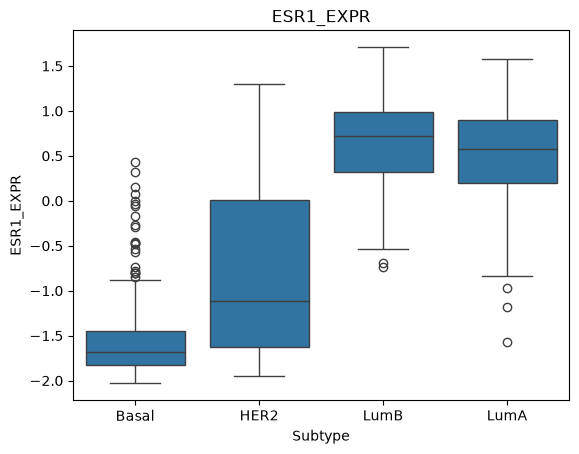

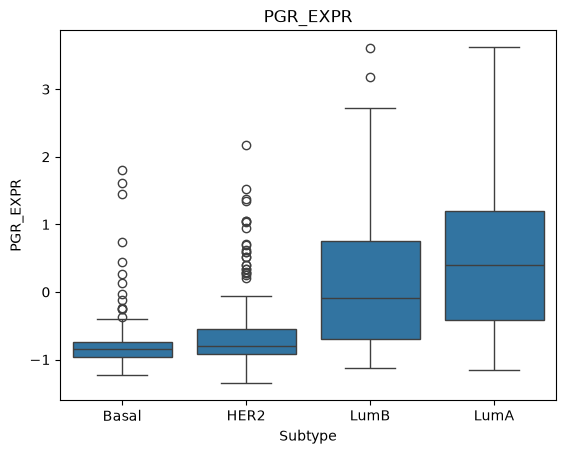

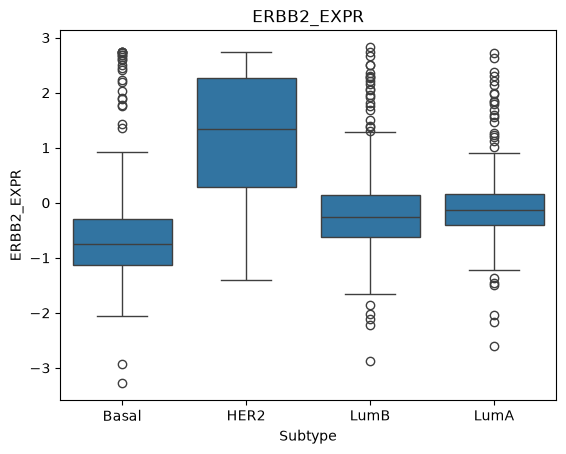

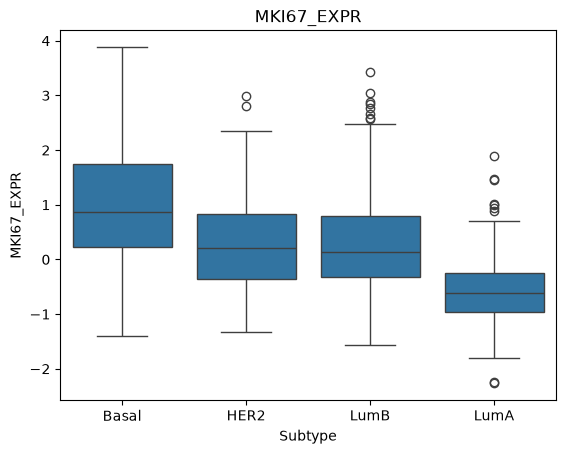

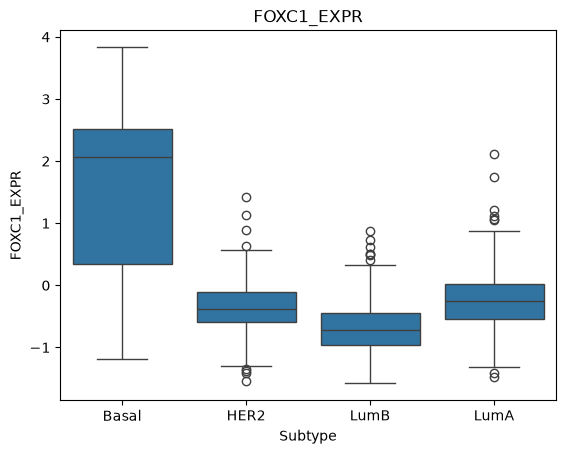

In [41]:
for gene in selected_genes:
    sns.boxplot(data=X, x="Subtype", y=gene)
    plt.title(gene)
    plt.show()

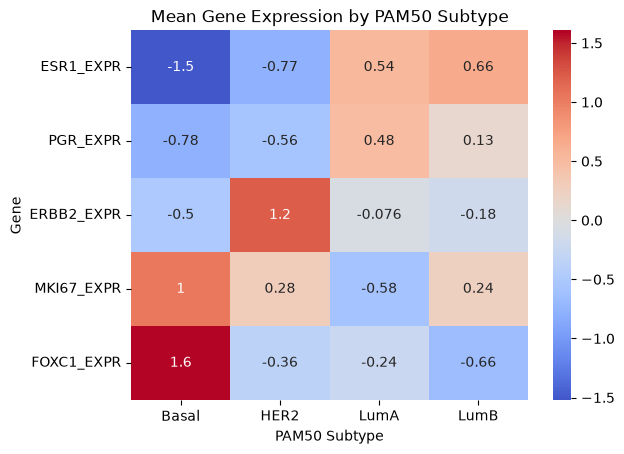

In [42]:
sns.heatmap(mean_expression.T, annot=True, cmap="coolwarm", center=0)
plt.title("Mean Gene Expression by PAM50 Subtype")
plt.xlabel("PAM50 Subtype")
plt.ylabel("Gene")
plt.show()

## CNV

In [43]:
selected_cnv = [
    "ERBB2_CNV",
    "MYC_CNV",
    "CCND1_CNV",
    "PIK3CA_CNV"
]

X_cnv = X_train_cnv[selected_cnv].copy()
X_cnv["Subtype"] = y_train.map(class_names)

print(X_cnv.head())

   ERBB2_CNV  MYC_CNV  CCND1_CNV  PIK3CA_CNV Subtype
0       -1.0      2.0        0.0         0.0   Basal
1        2.0      0.0        0.0         0.0   Basal
2        2.0     -1.0       -1.0         1.0    HER2
3        0.0      0.0        0.0         0.0    LumB
4        0.0      0.0        0.0         2.0   Basal


In [44]:
for gene in selected_cnv:
    table = pd.crosstab(X_cnv["Subtype"], X_cnv[gene], normalize="index") * 100

    print(gene)
    print(table.round(2))

ERBB2_CNV
ERBB2_CNV   -1.0    0.0    1.0    2.0
Subtype                              
Basal      40.85  43.66   4.23  11.27
HER2       12.58  26.49   7.28  53.64
LumA       10.52  76.08   8.87   4.54
LumB       16.82  59.46  12.31  11.41
MYC_CNV
MYC_CNV  -1.0    0.0    1.0    2.0
Subtype                           
Basal    2.82  28.17  29.11  39.91
HER2     1.99  37.09  23.18  37.75
LumA     1.24  66.80  20.00  11.96
LumB     0.60  42.04  25.53  31.83
CCND1_CNV
CCND1_CNV  -1.0    0.0    1.0    2.0
Subtype                             
Basal      6.10  70.89  17.37   5.63
HER2       7.95  61.59  13.91  16.56
LumA       1.86  77.94   6.39  13.81
LumB       1.20  49.25  16.82  32.73
PIK3CA_CNV
PIK3CA_CNV  -1.0    0.0    1.0   2.0
Subtype                             
Basal       3.76  56.81  29.58  9.86
HER2        3.97  72.85  17.88  5.30
LumA        1.65  88.45   8.04  1.86
LumB        2.40  82.88  12.01  2.70


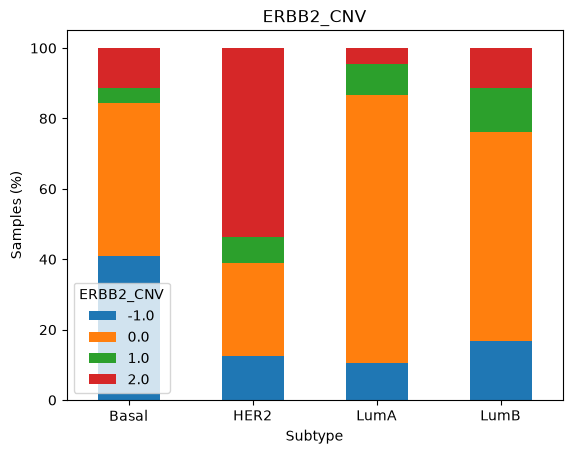

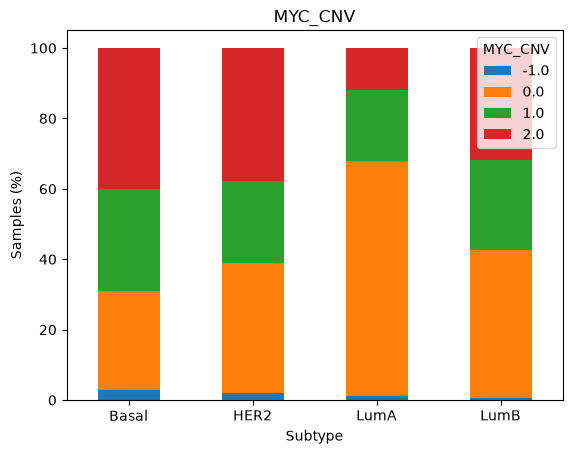

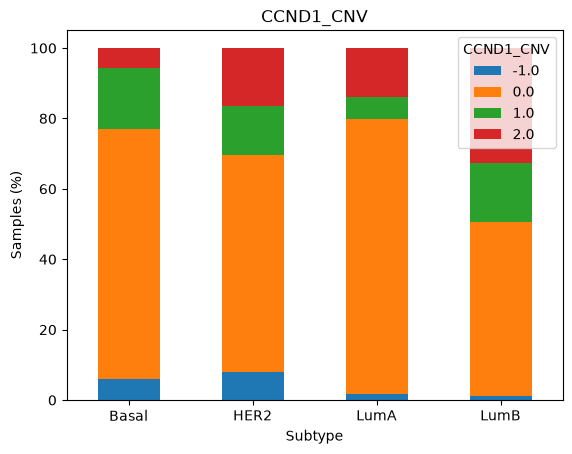

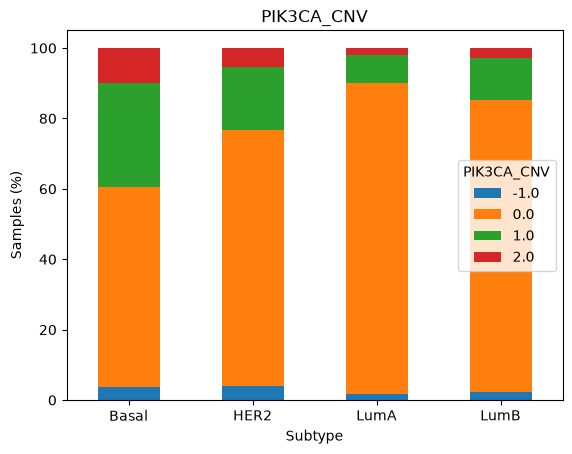

In [45]:
for gene in selected_cnv:
    table = pd.crosstab(X_cnv["Subtype"], X_cnv[gene], normalize="index") * 100

    table.plot(kind="bar", stacked=True)
    plt.title(gene)
    plt.ylabel("Samples (%)")
    plt.xticks(rotation=0)
    plt.show()

In [46]:
for gene in selected_cnv:
    rate = (X_cnv[gene] == 2).groupby(X_cnv["Subtype"]).mean() * 100

    print(gene)
    print(rate.round(2))

ERBB2_CNV
Subtype
Basal    11.27
HER2     53.64
LumA      4.54
LumB     11.41
Name: ERBB2_CNV, dtype: float64
MYC_CNV
Subtype
Basal    39.91
HER2     37.75
LumA     11.96
LumB     31.83
Name: MYC_CNV, dtype: float64
CCND1_CNV
Subtype
Basal     5.63
HER2     16.56
LumA     13.81
LumB     32.73
Name: CCND1_CNV, dtype: float64
PIK3CA_CNV
Subtype
Basal    9.86
HER2     5.30
LumA     1.86
LumB     2.70
Name: PIK3CA_CNV, dtype: float64


## SNP

In [47]:
selected_snp = [
    "TP53_SNP",
    "PIK3CA_SNP",
    "GATA3_SNP",
    "MAP3K1_SNP"
]

X_snp = X_train_snp[selected_snp].copy()
X_snp["Subtype"] = y_train.map(class_names)

print(X_snp.head())

   TP53_SNP  PIK3CA_SNP  GATA3_SNP  MAP3K1_SNP Subtype
0       1.0         0.0        0.0         0.0   Basal
1       0.0         0.0        0.0         0.0   Basal
2       1.0         1.0        0.0         0.0    HER2
3       0.0         1.0        1.0         0.0    LumB
4       1.0         0.0        0.0         0.0   Basal


In [48]:
mutation_rates = X_snp.groupby("Subtype")[selected_snp].mean() * 100

print(mutation_rates.round(2))

         TP53_SNP  PIK3CA_SNP  GATA3_SNP  MAP3K1_SNP
Subtype                                             
Basal       86.85       16.43       0.47        4.69
HER2        66.89       45.03       7.95        9.93
LumA        10.52       58.76      21.65       17.94
LumB        24.02       37.24      13.51        9.01


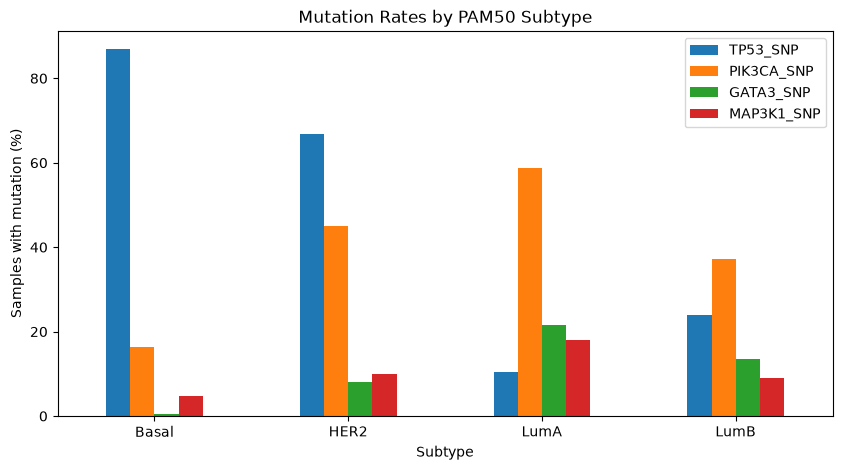

In [49]:
mutation_rates.plot(kind="bar", figsize=(10, 5))

plt.title("Mutation Rates by PAM50 Subtype")
plt.ylabel("Samples with mutation (%)")
plt.xticks(rotation=0)
plt.show()

## PCA Visulaisation

In [50]:
pca = PCA()
X_pca = pca.fit_transform(X_train_expr)

print("Original shape:", X_train_expr.shape)
print("PCA shape:", X_pca.shape)

Original shape: (1182, 15592)
PCA shape: (1182, 1182)


In [51]:
variance = pd.Series(pca.explained_variance_ratio_).cumsum()

n_90 = (variance < 0.90).sum() + 1
n_95 = (variance < 0.95).sum() + 1

print("Components for 90% variance:", n_90)
print("Components for 95% variance:", n_95)

Components for 90% variance: 740
Components for 95% variance: 923


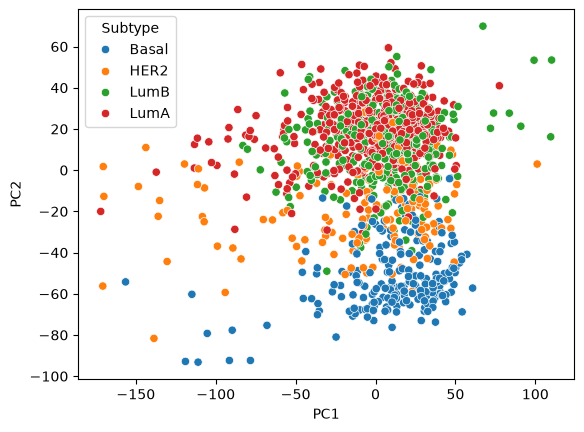

In [52]:
pca_df = pd.DataFrame(X_pca[:, :2], columns=["PC1", "PC2"])
pca_df["Subtype"] = y_train.map(class_names).values

sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Subtype")
plt.show()

# Stage 4 - Baseline Models

## Explore Variance

In [53]:
X_metabric = {
    "EXPR": pd.concat([X_train_expr, X_val_expr]),
    "CNV": pd.concat([X_train_cnv, X_val_cnv]),
    "SNP": pd.concat([X_train_snp, X_val_snp])
}

for name, X in X_metabric.items():
    variances = X.var(axis=0, ddof=0)

    print(
        f"{name} | Total: {X.shape[1]} | "
        f"Nonconstant: {(variances > 0).sum()} | "
        f"Constant: {(variances == 0).sum()}"
    )

EXPR | Total: 15592 | Nonconstant: 15592 | Constant: 0
CNV | Total: 15592 | Nonconstant: 15592 | Constant: 0
SNP | Total: 15592 | Nonconstant: 163 | Constant: 15429


In [54]:
X_tcga = {
    "EXPR": X_test_expr,
    "CNV": X_test_cnv,
    "SNP": X_test_snp
}

for name, X in X_tcga.items():
    variances = X.var(axis=0, ddof=0)

    print(
        f"{name} | Total: {X.shape[1]} | "
        f"Nonconstant: {(variances > 0).sum()} | "
        f"Constant: {(variances == 0).sum()}"
    )

EXPR | Total: 15592 | Nonconstant: 15581 | Constant: 11
CNV | Total: 15592 | Nonconstant: 15592 | Constant: 0
SNP | Total: 15592 | Nonconstant: 14195 | Constant: 1397


## Model 1: Expression 

In [55]:
model_expr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

In [56]:
model_expr.fit(X_train_expr, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](4,)","[0,1,2,3]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15592,)","['A1BG_EXPR','A1CF_EXPR','A2M_EXPR',...,'ZYX_EXPR','ZZEF1_EXPR', 'ZZZ3_EXPR']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15592
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [57]:
y_pred = model_expr.predict(X_val_expr)

evaluate_predictions(y_val, y_pred)

Accuracy: 0.8836
Balanced Accuracy: 0.8882
Macro F1: 0.8867
              precision    recall  f1-score   support

       Basal       0.99      0.93      0.96        89
        HER2       0.84      0.87      0.85        82
        LumA       0.92      0.87      0.89       202
        LumB       0.80      0.89      0.84       134

    accuracy                           0.88       507
   macro avg       0.89      0.89      0.89       507
weighted avg       0.89      0.88      0.88       507



{'Accuracy': 0.883629191321499,
 'Balanced Accuracy': 0.8882085658388525,
 'Macro F1': 0.8866664368786892}

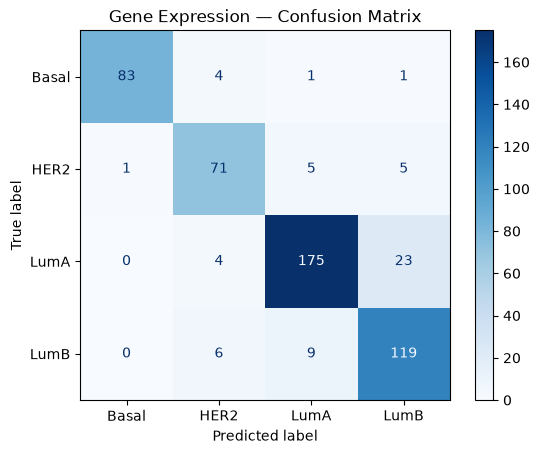

In [58]:
plot_confusion(y_val, y_pred, 'Gene Expression — Confusion Matrix')

## Model 2: CNV

In [59]:
model_cnv = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

In [60]:
model_cnv.fit(X_train_cnv, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](4,)","[0,1,2,3]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15592,)","['A1BG_CNV','A1CF_CNV','A2M_CNV',...,'ZYX_CNV','ZZEF1_CNV','ZZZ3_CNV']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15592
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [61]:
y_pred_cnv = model_cnv.predict(X_val_cnv)

evaluate_predictions(y_val, y_pred_cnv)

Accuracy: 0.5937
Balanced Accuracy: 0.5991
Macro F1: 0.5881
              precision    recall  f1-score   support

       Basal       0.68      0.85      0.76        89
        HER2       0.53      0.46      0.49        82
        LumA       0.64      0.62      0.63       202
        LumB       0.48      0.46      0.47       134

    accuracy                           0.59       507
   macro avg       0.58      0.60      0.59       507
weighted avg       0.59      0.59      0.59       507



{'Accuracy': 0.5936883629191322,
 'Balanced Accuracy': 0.5990833688126608,
 'Macro F1': 0.5881295977666213}

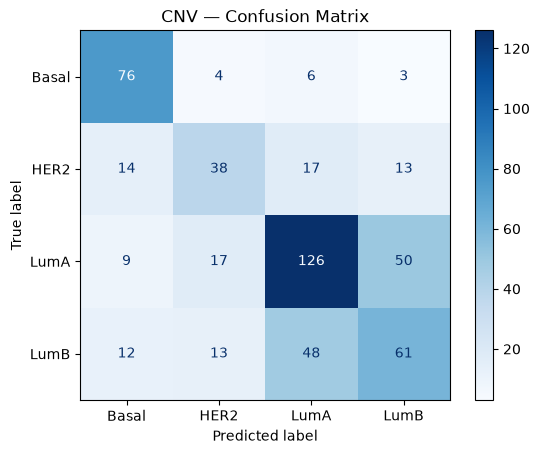

In [62]:
plot_confusion(y_val, y_pred_cnv, 'CNV — Confusion Matrix')

## Model 3: SNP

In [63]:
model_snp = Pipeline([
    ("variance", VarianceThreshold()),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

In [64]:
model_snp.fit(X_train_snp, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('variance', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](4,)","[0,1,2,3]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15592,)","['A1BG_SNP','A1CF_SNP','A2M_SNP',...,'ZYX_SNP','ZZEF1_SNP','ZZZ3_SNP']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15592
,"threshold threshold: float, default=0Features with a training-set variance lower than this threshold willbe removed. The default is to keep all features with non-zero variance,i.e. remove the features that have the same value in all samples.",0.0
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](15592,)","['A1BG_SNP','A1CF_SNP','A2M_SNP',...,'ZYX_SNP','ZZEF1_SNP','ZZZ3_SNP']"


In [65]:
y_pred_snp = model_snp.predict(X_val_snp)

evaluate_predictions(y_val, y_pred_snp)

Accuracy: 0.4576
Balanced Accuracy: 0.4127
Macro F1: 0.4057
              precision    recall  f1-score   support

       Basal       0.40      0.49      0.44        89
        HER2       0.29      0.22      0.25        82
        LumA       0.60      0.65      0.63       202
        LumB       0.33      0.28      0.31       134

    accuracy                           0.46       507
   macro avg       0.40      0.41      0.41       507
weighted avg       0.44      0.46      0.45       507



{'Accuracy': 0.45759368836291914,
 'Balanced Accuracy': 0.4127354134201884,
 'Macro F1': 0.40569654641939595}

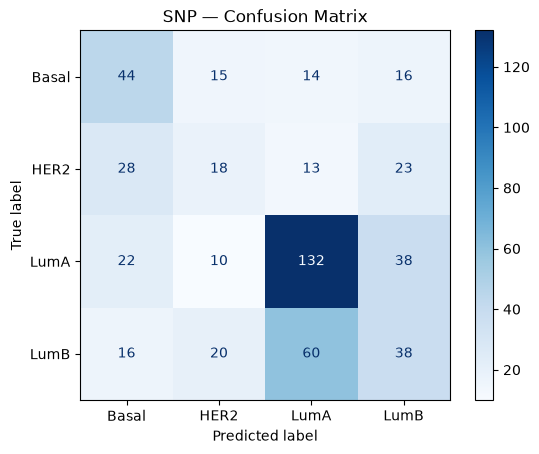

In [66]:
plot_confusion(y_val, y_pred_snp, 'SNP — Confusion Matrix')

## Model 4: Expression + CNV

In [67]:
X_train_expr_cnv = pd.concat([X_train_expr, X_train_cnv], axis=1)
X_val_expr_cnv = pd.concat([X_val_expr, X_val_cnv], axis=1)

print("Training:", X_train_expr_cnv.shape)
print("Validation:", X_val_expr_cnv.shape)

Training: (1182, 31184)
Validation: (507, 31184)


In [68]:
model_expr_cnv = Pipeline([
    ("variance", VarianceThreshold()),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

In [69]:
model_expr_cnv.fit(X_train_expr_cnv, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('variance', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](4,)","[0,1,2,3]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](31184,)","['A1BG_EXPR','A1CF_EXPR','A2M_EXPR',...,'ZYX_CNV','ZZEF1_CNV','ZZZ3_CNV']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,31184
,"threshold threshold: float, default=0Features with a training-set variance lower than this threshold willbe removed. The default is to keep all features with non-zero variance,i.e. remove the features that have the same value in all samples.",0.0
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](31184,)","['A1BG_EXPR','A1CF_EXPR','A2M_EXPR',...,'ZYX_CNV','ZZEF1_CNV','ZZZ3_CNV']"


In [70]:
y_pred_expr_cnv = model_expr_cnv.predict(X_val_expr_cnv)

evaluate_predictions(y_val, y_pred_expr_cnv)

Accuracy: 0.8462
Balanced Accuracy: 0.8534
Macro F1: 0.8469
              precision    recall  f1-score   support

       Basal       0.90      0.94      0.92        89
        HER2       0.80      0.82      0.81        82
        LumA       0.90      0.83      0.87       202
        LumB       0.76      0.82      0.79       134

    accuracy                           0.85       507
   macro avg       0.84      0.85      0.85       507
weighted avg       0.85      0.85      0.85       507



{'Accuracy': 0.8461538461538461,
 'Balanced Accuracy': 0.8533680215389249,
 'Macro F1': 0.8469130316644232}

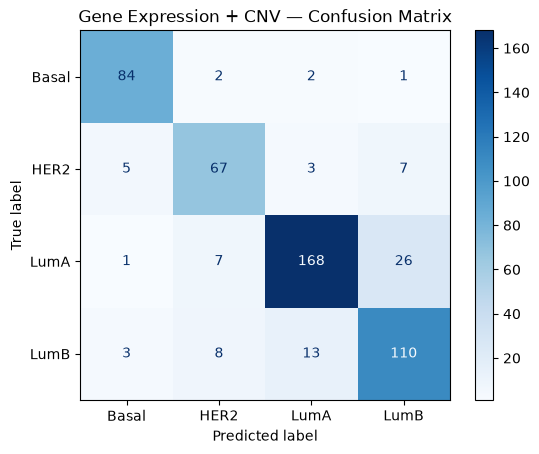

In [71]:
plot_confusion(y_val, y_pred_expr_cnv, 'Gene Expression + CNV — Confusion Matrix')

## Model 5: Expression + SNP

In [72]:
X_train_expr_snp = pd.concat([X_train_expr, X_train_snp], axis=1)
X_val_expr_snp = pd.concat([X_val_expr, X_val_snp], axis=1)

print("Training:", X_train_expr_snp.shape)
print("Validation:", X_val_expr_snp.shape)

Training: (1182, 31184)
Validation: (507, 31184)


In [73]:
model_expr_snp = Pipeline([
    ("variance", VarianceThreshold()),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

In [74]:
model_expr_snp.fit(X_train_expr_snp, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('variance', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](4,)","[0,1,2,3]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](31184,)","['A1BG_EXPR','A1CF_EXPR','A2M_EXPR',...,'ZYX_SNP','ZZEF1_SNP','ZZZ3_SNP']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,31184
,"threshold threshold: float, default=0Features with a training-set variance lower than this threshold willbe removed. The default is to keep all features with non-zero variance,i.e. remove the features that have the same value in all samples.",0.0
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](31184,)","['A1BG_EXPR','A1CF_EXPR','A2M_EXPR',...,'ZYX_SNP','ZZEF1_SNP','ZZZ3_SNP']"


In [75]:
y_pred_expr_snp = model_expr_snp.predict(X_val_expr_snp)

evaluate_predictions(y_val, y_pred_expr_snp)

Accuracy: 0.8817
Balanced Accuracy: 0.8861
Macro F1: 0.8852
              precision    recall  f1-score   support

       Basal       0.99      0.94      0.97        89
        HER2       0.84      0.85      0.85        82
        LumA       0.92      0.87      0.89       202
        LumB       0.79      0.88      0.83       134

    accuracy                           0.88       507
   macro avg       0.89      0.89      0.89       507
weighted avg       0.89      0.88      0.88       507



{'Accuracy': 0.8816568047337278,
 'Balanced Accuracy': 0.8861031024733016,
 'Macro F1': 0.8851953735513503}

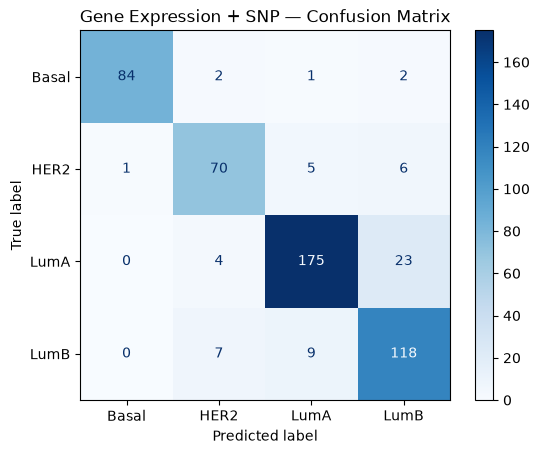

In [76]:
plot_confusion(y_val, y_pred_expr_snp, 'Gene Expression + SNP — Confusion Matrix')

## Model 6: CNV + SNP

In [77]:
X_train_cnv_snp = pd.concat([X_train_cnv, X_train_snp], axis=1)
X_val_cnv_snp = pd.concat([X_val_cnv, X_val_snp], axis=1)

print("Training:", X_train_cnv_snp.shape)
print("Validation:", X_val_cnv_snp.shape)

Training: (1182, 31184)
Validation: (507, 31184)


In [78]:
model_cnv_snp = Pipeline([
    ("variance", VarianceThreshold()),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

In [79]:
model_cnv_snp.fit(X_train_cnv_snp, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('variance', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](4,)","[0,1,2,3]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](31184,)","['A1BG_CNV','A1CF_CNV','A2M_CNV',...,'ZYX_SNP','ZZEF1_SNP','ZZZ3_SNP']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,31184
,"threshold threshold: float, default=0Features with a training-set variance lower than this threshold willbe removed. The default is to keep all features with non-zero variance,i.e. remove the features that have the same value in all samples.",0.0
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](31184,)","['A1BG_CNV','A1CF_CNV','A2M_CNV',...,'ZYX_SNP','ZZEF1_SNP','ZZZ3_SNP']"


In [80]:
y_pred_cnv_snp = model_cnv_snp.predict(X_val_cnv_snp)

evaluate_predictions(y_val, y_pred_cnv_snp)

Accuracy: 0.5838
Balanced Accuracy: 0.5880
Macro F1: 0.5825
              precision    recall  f1-score   support

       Basal       0.70      0.80      0.74        89
        HER2       0.53      0.49      0.51        82
        LumA       0.62      0.62      0.62       202
        LumB       0.47      0.45      0.46       134

    accuracy                           0.58       507
   macro avg       0.58      0.59      0.58       507
weighted avg       0.58      0.58      0.58       507



{'Accuracy': 0.5838264299802761,
 'Balanced Accuracy': 0.5880326905638785,
 'Macro F1': 0.58251592576735}

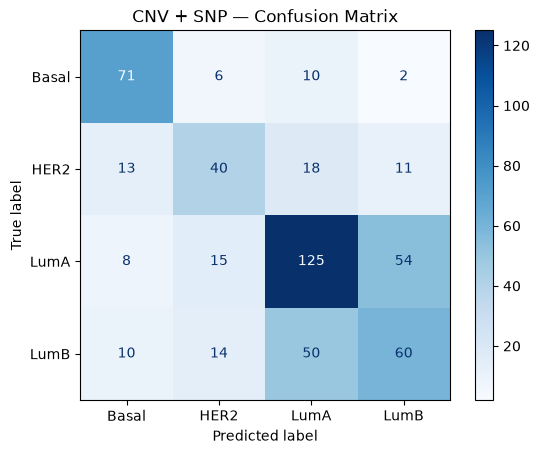

In [81]:
plot_confusion(y_val, y_pred_cnv_snp, 'CNV + SNP — Confusion Matrix')

## Model 7: EXPR + CNV + SNP

In [82]:
X_train_all = pd.concat([X_train_expr, X_train_cnv, X_train_snp], axis=1)
X_val_all = pd.concat([X_val_expr, X_val_cnv, X_val_snp], axis=1)

print("Training:", X_train_all.shape)
print("Validation:", X_val_all.shape)

Training: (1182, 46776)
Validation: (507, 46776)


In [83]:
model_all = Pipeline([
    ("variance", VarianceThreshold()),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

In [84]:
model_all.fit(X_train_all, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('variance', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](4,)","[0,1,2,3]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](46776,)","['A1BG_EXPR','A1CF_EXPR','A2M_EXPR',...,'ZYX_SNP','ZZEF1_SNP','ZZZ3_SNP']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,46776
,"threshold threshold: float, default=0Features with a training-set variance lower than this threshold willbe removed. The default is to keep all features with non-zero variance,i.e. remove the features that have the same value in all samples.",0.0
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](46776,)","['A1BG_EXPR','A1CF_EXPR','A2M_EXPR',...,'ZYX_SNP','ZZEF1_SNP','ZZZ3_SNP']"


In [85]:
y_pred_all = model_all.predict(X_val_all)

evaluate_predictions(y_val, y_pred_all)

Accuracy: 0.8481
Balanced Accuracy: 0.8546
Macro F1: 0.8484
              precision    recall  f1-score   support

       Basal       0.90      0.94      0.92        89
        HER2       0.80      0.82      0.81        82
        LumA       0.90      0.84      0.87       202
        LumB       0.77      0.82      0.79       134

    accuracy                           0.85       507
   macro avg       0.84      0.85      0.85       507
weighted avg       0.85      0.85      0.85       507



{'Accuracy': 0.8481262327416174,
 'Balanced Accuracy': 0.8546056453013011,
 'Macro F1': 0.8483560667491978}

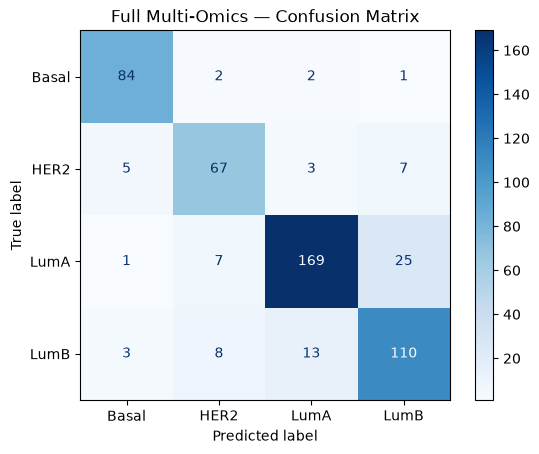

In [86]:
plot_confusion(y_val, y_pred_all, 'Full Multi-Omics — Confusion Matrix')

## Summary


### Baseline Models — Overall Performance

**Dataset:** METABRIC Validation (n = 507)

| Model | Accuracy | Balanced Accuracy | Macro F1 |
|---|---:|---:|---:|
| **Expression** | **0.8836** | **0.8882** | **0.8867** |
| CNV | 0.5937 | 0.5991 | 0.5881 |
| SNP | 0.4576 | 0.4127 | 0.4057 |
| Expression + CNV | 0.8462 | 0.8534 | 0.8469 |
| Expression + SNP | 0.8817 | 0.8861 | 0.8852 |
| CNV + SNP | 0.5838 | 0.5880 | 0.5825 |
| Multi-Omics (EXPR + CNV + SNP) | 0.8481 | 0.8546 | 0.8484 |

# Stage 5 - Model Optimisation

## SelectKBest (ANOVA) - Expression Only
**Accuracy 0.867; Macro F1 0.866**

In [180]:
model_expr_fs = Pipeline([
    ("selection", SelectKBest(score_func=f_classif)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

In [181]:
param_grid = {
    "selection__k": [100, 500, 1000, 2000]
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

grid_expr_fs = GridSearchCV(
    model_expr_fs,
    param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=2,
    verbose=2
)

grid_expr_fs.fit(X_train_expr, y_train)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV] END ...................................selection__k=100; total time=   1.3s
[CV] END ...................................selection__k=100; total time=   1.3s
[CV] END ...................................selection__k=100; total time=   1.0s
[CV] END ...................................selection__k=500; total time=   1.0s
[CV] END ...................................selection__k=500; total time=   0.9s
[CV] END ...................................selection__k=500; total time=   1.0s
[CV] END ..................................selection__k=1000; total time=   1.0s
[CV] END ..................................selection__k=1000; total time=   0.9s
[CV] END ..................................selection__k=1000; total time=   0.9s
[CV] END ..................................selection__k=2000; total time=   1.0s
[CV] END ..................................selection__k=2000; total time=   0.9s
[CV] END ..................................select

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=2000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'selection__k': [100, 500, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how

In [182]:
results_fs = pd.DataFrame(grid_expr_fs.cv_results_)

results_fs[[
    "param_selection__k",
    "mean_test_score",
    "std_test_score",
    "mean_fit_time"
]].sort_values("mean_test_score", ascending=False)

,param_selection__k,mean_test_score,std_test_score,mean_fit_time
3,2000,0.833800,0.010027,0.808945
0,100,0.826729,0.005532,1.000957
2,1000,0.825629,0.005938,0.830001
1,500,0.821318,0.012584,0.795568


In [183]:
print("Best number of genes:", grid_expr_fs.best_params_)
print("Best CV Macro F1:", grid_expr_fs.best_score_)

Best number of genes: {'selection__k': 2000}
Best CV Macro F1: 0.8337996180693247


Accuracy: 0.8679
Balanced Accuracy: 0.8710
Macro F1: 0.8662
              precision    recall  f1-score   support

       Basal       0.94      0.93      0.94        89
        HER2       0.79      0.83      0.81        82
        LumA       0.93      0.86      0.89       202
        LumB       0.79      0.87      0.83       134

    accuracy                           0.87       507
   macro avg       0.86      0.87      0.87       507
weighted avg       0.87      0.87      0.87       507



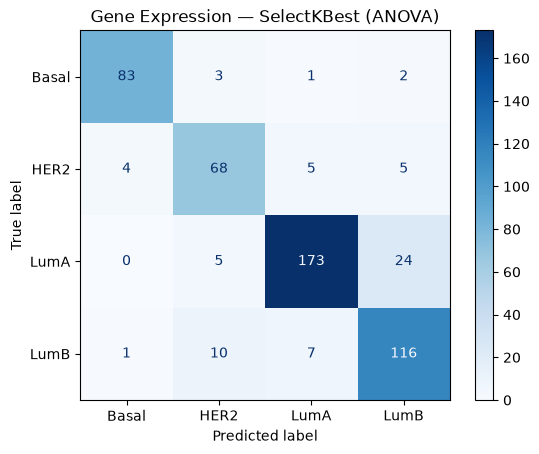

In [184]:
y_pred_expr_fs = grid_expr_fs.predict(X_val_expr)

evaluate_predictions(y_val, y_pred_expr_fs)

plot_confusion(y_val, y_pred_expr_fs, 'Gene Expression — SelectKBest (ANOVA)')

## Regularisation L1 and L2 - Expression Only
- **L1 = Accuracy 0.885; Macro F1 0.884**
- **L2 = Accuracy: 0.871; Macro F1 0.873**

In [92]:
model_saga = Pipeline([
    ("selection", SelectKBest(f_classif, k=2000)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        solver="saga",
        l1_ratio=1,
        C=0.1,
        max_iter=1000,
        random_state=42
    ))
])

model_saga.fit(X_train_expr, y_train)

print("Iterations:", model_saga.named_steps["model"].n_iter_)

Iterations: [1000]


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [93]:
model_saga = Pipeline([
    ("selection", SelectKBest(score_func=f_classif, k=2000)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        solver="saga",
        l1_ratio=1,
        C=0.1,
        max_iter=5000,
        tol=0.0001,
        random_state=42
    ))
])

model_saga.fit(X_train_expr, y_train)

# Results
print("Iterations:", model_saga.named_steps["model"].n_iter_)

Iterations: [2899]


In [94]:
coef = model_saga.named_steps["model"].coef_

print("Coefficient matrix shape:", coef.shape)
print("Nonzero coefficients:", np.count_nonzero(coef))
print("Genes retained:", np.count_nonzero(np.any(coef != 0, axis=0)))
print("Genes eliminated:", coef.shape[1] - np.count_nonzero(np.any(coef != 0, axis=0)))

Coefficient matrix shape: (4, 2000)
Nonzero coefficients: 254
Genes retained: 236
Genes eliminated: 1764


Accuracy: 0.8856
Balanced Accuracy: 0.8857
Macro F1: 0.8841
              precision    recall  f1-score   support

       Basal       0.93      0.94      0.94        89
        HER2       0.87      0.82      0.84        82
        LumA       0.94      0.87      0.90       202
        LumB       0.80      0.91      0.85       134

    accuracy                           0.89       507
   macro avg       0.89      0.89      0.88       507
weighted avg       0.89      0.89      0.89       507



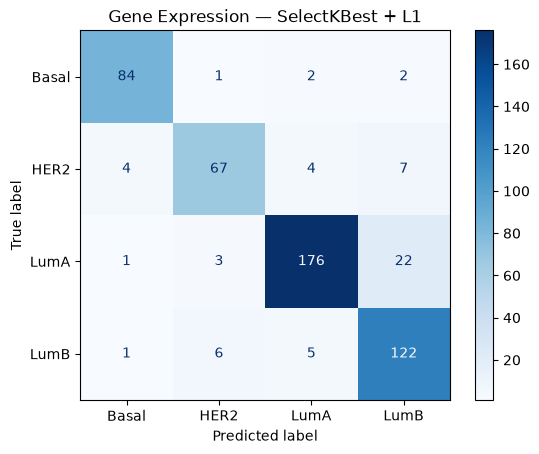

In [95]:
y_pred_saga = model_saga.predict(X_val_expr)

evaluate_predictions(y_val, y_pred_saga)

plot_confusion(y_val, y_pred_saga, 'Gene Expression — SelectKBest + L1')

In [96]:
model_l2 = Pipeline([
    ("selection", SelectKBest(f_classif, k=2000)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        solver="saga",
        l1_ratio=0,
        C=0.1,
        max_iter=5000,
        tol=0.0001,
        random_state=42
    ))
])

model_l2.fit(X_train_expr, y_train)

print("Iterations:", model_l2.named_steps["model"].n_iter_)

Iterations: [455]


Accuracy: 0.8718
Balanced Accuracy: 0.8763
Macro F1: 0.8731
              precision    recall  f1-score   support

       Basal       0.95      0.94      0.95        89
        HER2       0.83      0.83      0.83        82
        LumA       0.93      0.85      0.89       202
        LumB       0.78      0.88      0.83       134

    accuracy                           0.87       507
   macro avg       0.87      0.88      0.87       507
weighted avg       0.88      0.87      0.87       507

Genes retained: 2000


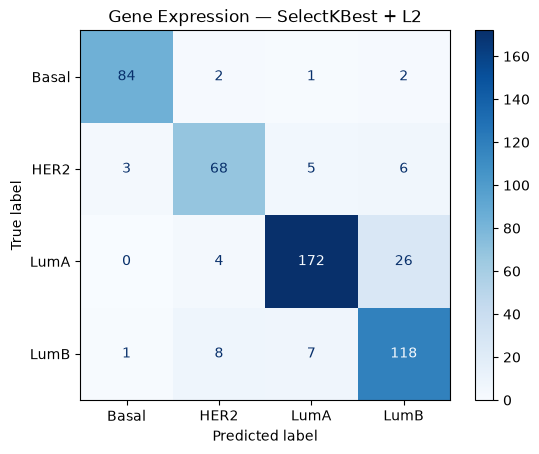

In [97]:
# Predictions
y_pred_l2 = model_l2.predict(X_val_expr)

# Evaluation
evaluate_predictions(y_val, y_pred_l2)

# Number of retained genes
coef_l2 = model_l2.named_steps["model"].coef_

print("Genes retained:", np.count_nonzero(np.any(coef_l2 != 0, axis=0)))

# Confusion matrix
plot_confusion(y_val, y_pred_l2, 'Gene Expression — SelectKBest + L2')

## Elastic Net - Expression Only
**Accuracy: 0.881; Macro F1: 0.878**

In [98]:
model_en = Pipeline([
    ("selection", SelectKBest(f_classif, k=2000)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        solver="saga",
        l1_ratio=0.5,
        C=0.1,
        max_iter=5000,
        tol=0.0001,
        random_state=42
    ))
])


model_en.fit(X_train_expr, y_train)

print("Iterations:", model_en.named_steps["model"].n_iter_)

coef_en = model_en.named_steps["model"].coef_

print("Genes retained:", np.count_nonzero(np.any(coef_en != 0, axis=0)))
print("Genes eliminated:", coef_en.shape[1] - np.count_nonzero(np.any(coef_en != 0, axis=0)))

Iterations: [1548]
Genes retained: 437
Genes eliminated: 1563


Accuracy: 0.8817
Balanced Accuracy: 0.8822
Macro F1: 0.8787
              precision    recall  f1-score   support

       Basal       0.93      0.93      0.93        89
        HER2       0.83      0.83      0.83        82
        LumA       0.94      0.87      0.90       202
        LumB       0.81      0.90      0.85       134

    accuracy                           0.88       507
   macro avg       0.88      0.88      0.88       507
weighted avg       0.89      0.88      0.88       507



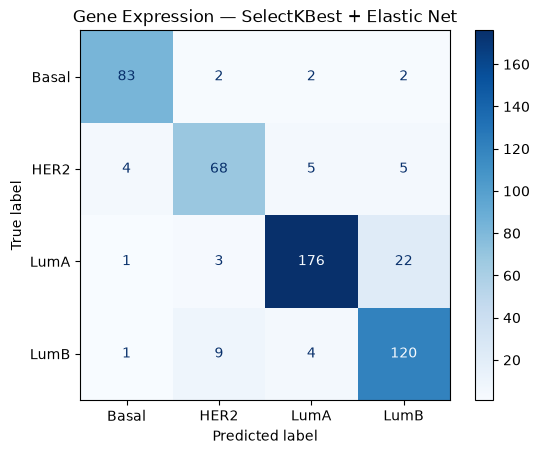

In [99]:
# Predictions
y_pred_en = model_en.predict(X_val_expr)

# Evaluation
evaluate_predictions(y_val, y_pred_en)

# Confusion matrix
plot_confusion(y_val, y_pred_en, 'Gene Expression — SelectKBest + Elastic Net')

## Random Forest - Expression Only
**Accuracy: 0.857; Macro F1: 0.863**

In [100]:
model_rf = Pipeline([
    ("selection", SelectKBest(f_classif, k=2000)),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=2
    ))
])

model_rf.fit(X_train_expr, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('selection', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](4,)","[0,1,2,3]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15592,)","['A1BG_EXPR','A1CF_EXPR','A2M_EXPR',...,'ZYX_EXPR','ZZEF1_EXPR', 'ZZZ3_EXPR']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15592
,"k k: int or ""all"", default=10Number of top features to select.The ""all"" option bypasses selection, for use in a parameter search.",2000
,"score_func score_func: callable, default=f_classifFunction taking two arrays X and y, and returning a pair of arrays(scores, pvalues) or a single array with scores.Default is f_classif (see below ""See Also""). The default function onlyworks with classification tasks... versionadded:: 0.18",<function f_c...t 0x14a7096c0>
Name,Type,Value


Accuracy: 0.8580
Balanced Accuracy: 0.8568
Macro F1: 0.8631
              precision    recall  f1-score   support

       Basal       0.98      0.92      0.95        89
        HER2       0.91      0.76      0.83        82
        LumA       0.90      0.83      0.87       202
        LumB       0.73      0.92      0.81       134

    accuracy                           0.86       507
   macro avg       0.88      0.86      0.86       507
weighted avg       0.87      0.86      0.86       507



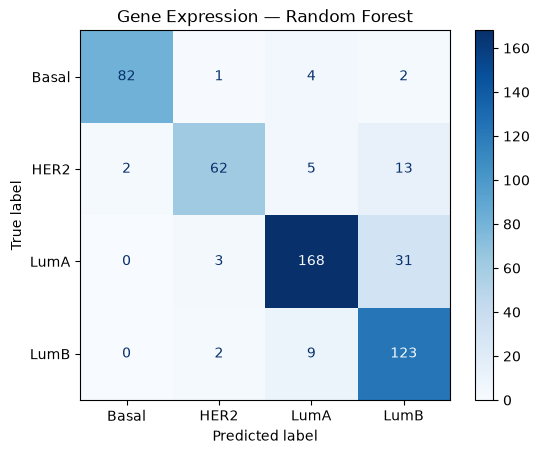

In [101]:
y_pred_rf = model_rf.predict(X_val_expr)

evaluate_predictions(y_val, y_pred_rf)

plot_confusion(y_val, y_pred_rf, 'Gene Expression — Random Forest')

## HistGradientBoostingClassifier - Expression Only
**Accuracy: 0.889; Macro F1: 0.889**

In [102]:
model_hgb = Pipeline([
    ("selection", SelectKBest(f_classif, k=2000)),
    ("model", HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=15,
        random_state=42
    ))
])

model_hgb.fit(X_train_expr, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('selection', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](4,)","[0,1,2,3]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15592,)","['A1BG_EXPR','A1CF_EXPR','A2M_EXPR',...,'ZYX_EXPR','ZZEF1_EXPR', 'ZZZ3_EXPR']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15592
,"k k: int or ""all"", default=10Number of top features to select.The ""all"" option bypasses selection, for use in a parameter search.",2000
,"score_func score_func: callable, default=f_classifFunction taking two arrays X and y, and returning a pair of arrays(scores, pvalues) or a single array with scores.Default is f_classif (see below ""See Also""). The default function onlyworks with classification tasks... versionadded:: 0.18",<function f_c...t 0x14a7096c0>
Name,Type,Value


Accuracy: 0.8895
Balanced Accuracy: 0.8888
Macro F1: 0.8892
              precision    recall  f1-score   support

       Basal       0.93      0.94      0.94        89
        HER2       0.92      0.80      0.86        82
        LumA       0.95      0.87      0.91       202
        LumB       0.78      0.94      0.85       134

    accuracy                           0.89       507
   macro avg       0.90      0.89      0.89       507
weighted avg       0.90      0.89      0.89       507



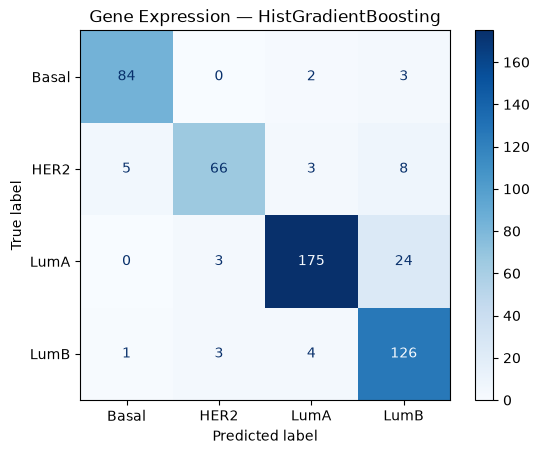

In [103]:
y_pred_hgb = model_hgb.predict(X_val_expr)

evaluate_predictions(y_val, y_pred_hgb)

plot_confusion(y_val, y_pred_hgb, 'Gene Expression — HistGradientBoosting')

### HGB Grid Search

In [104]:
# Pipeline
model_hgb_grid = Pipeline([
    ("selection", SelectKBest(f_classif, k=2000)),
    ("model", HistGradientBoostingClassifier(
        max_iter=100,
        random_state=42
    ))
])

# Hyperparameter grid
param_grid = {
    "model__learning_rate": [0.05, 0.1],
    "model__max_leaf_nodes": [7, 15],
    "model__l2_regularization": [0, 1]
}

# Cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Grid search
grid_hgb = GridSearchCV(
    estimator=model_hgb_grid,
    param_grid=param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=2,
    verbose=2
)

# Fit on METABRIC training data only
grid_hgb.fit(X_train_expr, y_train)

print("Best parameters:", grid_hgb.best_params_)
print("Best CV Macro F1:", grid_hgb.best_score_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV] END model__l2_regularization=0, model__learning_rate=0.05, model__max_leaf_nodes=7; total time=  10.3s
[CV] END model__l2_regularization=0, model__learning_rate=0.05, model__max_leaf_nodes=7; total time=  10.3s
[CV] END model__l2_regularization=0, model__learning_rate=0.05, model__max_leaf_nodes=7; total time=   9.3s
[CV] END model__l2_regularization=0, model__learning_rate=0.05, model__max_leaf_nodes=15; total time=  15.8s
[CV] END model__l2_regularization=0, model__learning_rate=0.05, model__max_leaf_nodes=15; total time=  15.6s
[CV] END model__l2_regularization=0, model__learning_rate=0.05, model__max_leaf_nodes=15; total time=  15.6s
[CV] END model__l2_regularization=0, model__learning_rate=0.1, model__max_leaf_nodes=7; total time=   9.1s
[CV] END model__l2_regularization=0, model__learning_rate=0.1, model__max_leaf_nodes=7; total time=   9.2s
[CV] END model__l2_regularization=0, model__learning_rate=0.1, model__max_l

In [105]:
results_hgb = pd.DataFrame(grid_hgb.cv_results_)

results_hgb[[
    "param_model__learning_rate",
    "param_model__max_leaf_nodes",
    "param_model__l2_regularization",
    "mean_test_score",
    "std_test_score",
    "mean_fit_time"
]].sort_values("mean_test_score", ascending=False)

,param_model__learning_rate,param_model__max_leaf_nodes,param_model__l2_regularization,mean_test_score,std_test_score,mean_fit_time
5,0.05,15,1,0.850369,0.002568,14.648530
1,0.05,15,0,0.848638,0.006413,15.452417
4,0.05,7,1,0.846460,0.010804,10.649685
6,0.10,7,1,0.846234,0.003760,9.456491
3,0.10,15,0,0.844305,0.005858,13.997807
7,0.10,15,1,0.843852,0.006827,12.674653
0,0.05,7,0,0.842557,0.011584,9.785835
2,0.10,7,0,0.841626,0.006192,8.935560


Accuracy: 0.8797
Balanced Accuracy: 0.8808
Macro F1: 0.8799
              precision    recall  f1-score   support

       Basal       0.94      0.94      0.94        89
        HER2       0.88      0.79      0.83        82
        LumA       0.93      0.85      0.89       202
        LumB       0.78      0.94      0.85       134

    accuracy                           0.88       507
   macro avg       0.88      0.88      0.88       507
weighted avg       0.89      0.88      0.88       507



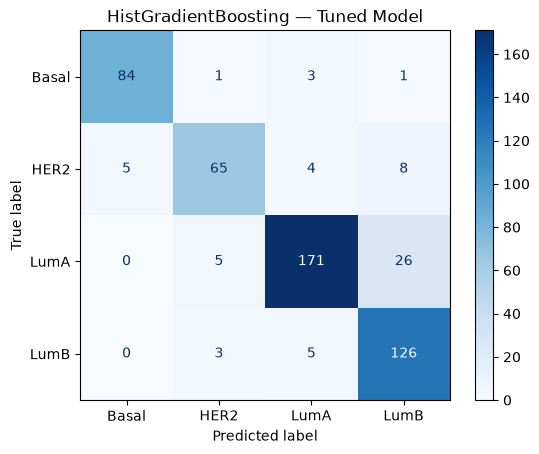

In [106]:
# Best model predictions
y_pred_hgb_grid = grid_hgb.predict(X_val_expr)

# Evaluation
evaluate_predictions(y_val, y_pred_hgb_grid)

# Confusion matrix
plot_confusion(y_val, y_pred_hgb_grid, 'HistGradientBoosting — Tuned Model')

## SelectKBest (mutual_info_classif) - Expression Only
- HGB: **Accuracy: 0.885; Macro F1: 0.883**
- LR: **Accuracy: 0.8856015779092702; Macro F1: 0.885**

In [107]:
# Pipeline
model_hgb_mi = Pipeline([
    ("selection", SelectKBest(
        score_func=mutual_info_classif,
        k=2000
    )),
    ("model", HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=15,
        random_state=42
    ))
])

# Training
model_hgb_mi.fit(X_train_expr, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('selection', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](4,)","[0,1,2,3]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15592,)","['A1BG_EXPR','A1CF_EXPR','A2M_EXPR',...,'ZYX_EXPR','ZZEF1_EXPR', 'ZZZ3_EXPR']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15592
,"score_func score_func: callable, default=f_classifFunction taking two arrays X and y, and returning a pair of arrays(scores, pvalues) or a single array with scores.Default is f_classif (see below ""See Also""). The default function onlyworks with classification tasks... versionadded:: 0.18",<function mut...t 0x14a31f6a0>
,"k k: int or ""all"", default=10Number of top features to select.The ""all"" option bypasses selection, for use in a parameter search.",2000
Name,Type,Value


Accuracy: 0.8915
Balanced Accuracy: 0.8895
Macro F1: 0.8910
              precision    recall  f1-score   support

       Basal       0.92      0.94      0.93        89
        HER2       0.94      0.79      0.86        82
        LumA       0.94      0.87      0.90       202
        LumB       0.80      0.96      0.87       134

    accuracy                           0.89       507
   macro avg       0.90      0.89      0.89       507
weighted avg       0.90      0.89      0.89       507



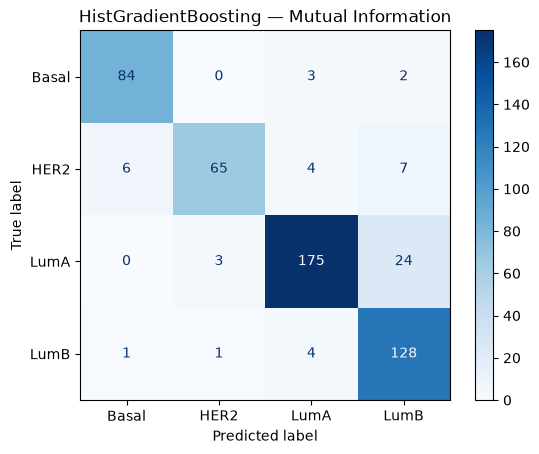

In [108]:
y_pred_hgb_mi = model_hgb_mi.predict(X_val_expr)

evaluate_predictions(y_val, y_pred_hgb_mi)

plot_confusion(y_val, y_pred_hgb_mi, 'HistGradientBoosting — Mutual Information')

In [109]:

model_l1_mi = Pipeline([
    ("selection", SelectKBest(
            score_func=mutual_info_classif,
            k=2000
        )),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        solver="saga",
        l1_ratio=1,
        C=0.1,
        max_iter=5000,
        tol=0.0001,
        random_state=42
    ))
])

model_l1_mi.fit(X_train_expr, y_train)

print("Iterations:", model_l1_mi.named_steps["model"].n_iter_)

coef_l1_mi = model_l1_mi.named_steps["model"].coef_

print("Genes retained:", np.count_nonzero(np.any(coef_l1_mi != 0, axis=0)))

Iterations: [2735]
Genes retained: 231


Accuracy: 0.8876
Balanced Accuracy: 0.8911
Macro F1: 0.8872
              precision    recall  f1-score   support

       Basal       0.95      0.94      0.95        89
        HER2       0.84      0.84      0.84        82
        LumA       0.95      0.86      0.90       202
        LumB       0.80      0.92      0.85       134

    accuracy                           0.89       507
   macro avg       0.89      0.89      0.89       507
weighted avg       0.89      0.89      0.89       507



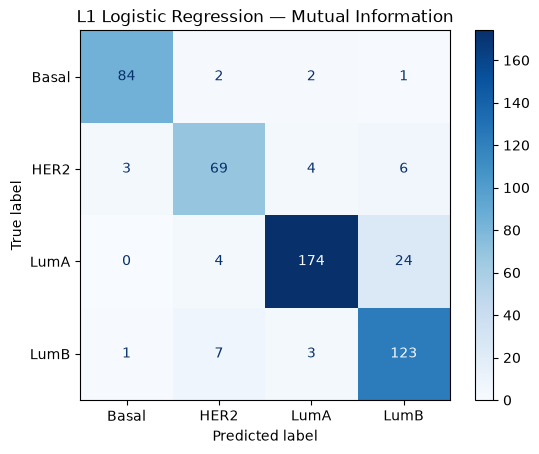

In [110]:
y_pred_l1_mi = model_l1_mi.predict(X_val_expr)

evaluate_predictions(y_val, y_pred_l1_mi)

plot_confusion(y_val, y_pred_l1_mi, 'L1 Logistic Regression — Mutual Information')

## RFE - Expression Only
**Accuracy: 0.879; Macro F1: 0.878**

In [111]:
model_rfe = Pipeline([
    ("selection", SelectKBest(f_classif, k=500)),
    ("scaler", StandardScaler()),
    ("rfe", RFE(
        estimator=LogisticRegression(
            solver="lbfgs",
            C=0.1,
            max_iter=2000
        ),
        n_features_to_select=200,
        step=50
    )),
    ("model", LogisticRegression(
        solver="lbfgs",
        C=0.1,
        max_iter=2000
    ))
])


model_rfe.fit(X_train_expr, y_train)

print("Genes selected by RFE:", model_rfe.named_steps["rfe"].n_features_)

Genes selected by RFE: 200


Accuracy: 0.8797
Balanced Accuracy: 0.8815
Macro F1: 0.8787
              precision    recall  f1-score   support

       Basal       0.95      0.91      0.93        89
        HER2       0.83      0.84      0.84        82
        LumA       0.94      0.86      0.90       202
        LumB       0.79      0.92      0.85       134

    accuracy                           0.88       507
   macro avg       0.88      0.88      0.88       507
weighted avg       0.89      0.88      0.88       507



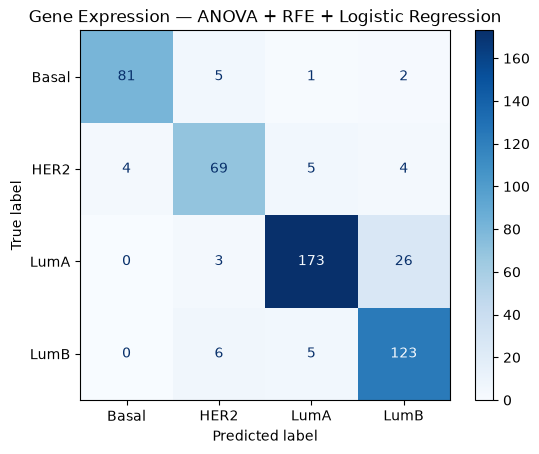

In [112]:
y_pred_rfe = model_rfe.predict(X_val_expr)

evaluate_predictions(y_val, y_pred_rfe)

plot_confusion(y_val, y_pred_rfe, 'Gene Expression — ANOVA + RFE + Logistic Regression')

## Expr + CNV
- **HGB: Accuracy: 0.889; Macro F1: 0.889**
- **Accuracy: 0.887; Macro F1: 0.888**

Accuracy: 0.8895
Balanced Accuracy: 0.8888
Macro F1: 0.8892
              precision    recall  f1-score   support

       Basal       0.93      0.94      0.94        89
        HER2       0.92      0.80      0.86        82
        LumA       0.95      0.87      0.91       202
        LumB       0.78      0.94      0.85       134

    accuracy                           0.89       507
   macro avg       0.90      0.89      0.89       507
weighted avg       0.90      0.89      0.89       507



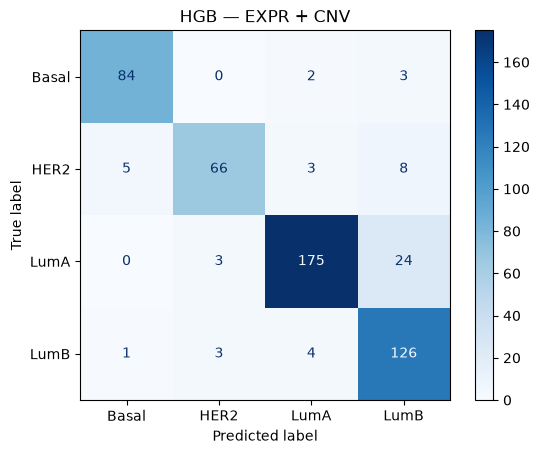

In [113]:
# Feature selection
preprocessor = ColumnTransformer([
    ("expr", Pipeline([
        ("selection", SelectKBest(f_classif, k=2000))
    ]), X_train_expr.columns.tolist()),

    ("cnv", Pipeline([
        ("selection", SelectKBest(f_classif, k=500))
    ]), X_train_cnv.columns.tolist())
])
# Model
model_hgb_expr_cnv = Pipeline([
    ("selection", preprocessor),
    ("model", HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=15,
        random_state=42
    ))
])

# Training
model_hgb_expr_cnv.fit(X_train_expr_cnv, y_train)

# Evaluation
y_pred_hgb_expr_cnv = model_hgb_expr_cnv.predict(X_val_expr_cnv)

evaluate_predictions(y_val, y_pred_hgb_expr_cnv)

plot_confusion(y_val, y_pred_hgb_expr_cnv, 'HGB — EXPR + CNV')

Accuracy: 0.8876
Balanced Accuracy: 0.8905
Macro F1: 0.8883
              precision    recall  f1-score   support

       Basal       0.94      0.94      0.94        89
        HER2       0.87      0.84      0.86        82
        LumA       0.94      0.87      0.90       202
        LumB       0.80      0.91      0.85       134

    accuracy                           0.89       507
   macro avg       0.89      0.89      0.89       507
weighted avg       0.89      0.89      0.89       507



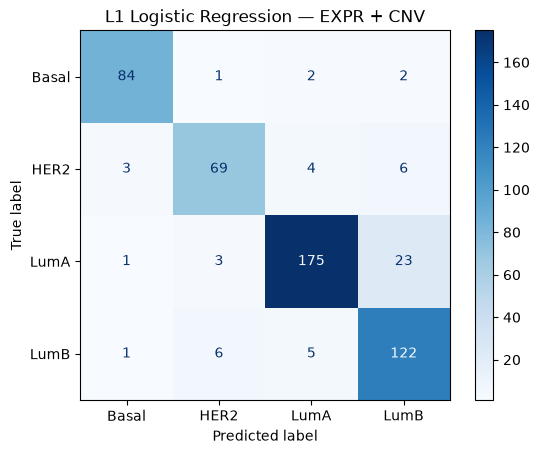

In [114]:
preprocessor = ColumnTransformer([
    ("expr", Pipeline([
        ("selection", SelectKBest(f_classif, k=2000))
    ]), X_train_expr.columns.tolist()),

    ("cnv", Pipeline([
        ("selection", SelectKBest(f_classif, k=500))
    ]), X_train_cnv.columns.tolist())
])

model_l1_expr_cnv = Pipeline([
    ("preprocessor", preprocessor),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        solver="saga",
        l1_ratio=1,
        C=0.1,
        max_iter=5000,
        tol=0.0001,
        random_state=42
    ))
])

# Training
model_l1_expr_cnv.fit(X_train_expr_cnv, y_train)

# Evaluation
y_pred_l1_expr_cnv = model_l1_expr_cnv.predict(X_val_expr_cnv)

evaluate_predictions(y_val, y_pred_l1_expr_cnv)

plot_confusion(y_val, y_pred_l1_expr_cnv, 'L1 Logistic Regression — EXPR + CNV')

## Expr + SNP
- **HGB: Accuracy: 0.883; Macro F1: 0.886**
- **Accuracy: 0.889; Macro F1: 0.887**

Accuracy: 0.8836
Balanced Accuracy: 0.8876
Macro F1: 0.8869
              precision    recall  f1-score   support

       Basal       0.96      0.97      0.96        89
        HER2       0.90      0.80      0.85        82
        LumA       0.94      0.85      0.89       202
        LumB       0.77      0.93      0.84       134

    accuracy                           0.88       507
   macro avg       0.89      0.89      0.89       507
weighted avg       0.89      0.88      0.88       507



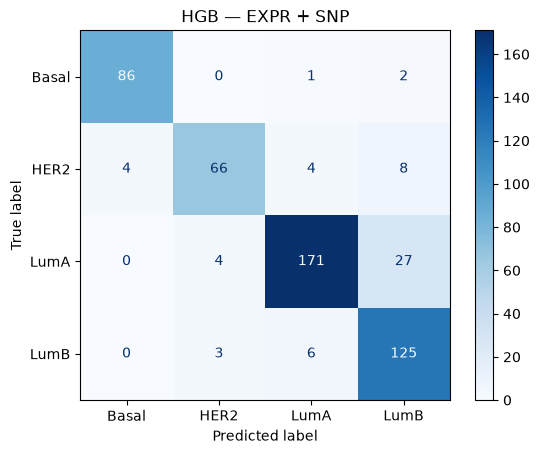

In [115]:
# Preprocessing
preprocessor_expr_snp = ColumnTransformer([
    ("expr", Pipeline([
        ("selection", SelectKBest(f_classif, k=2000))
    ]), X_train_expr.columns.tolist()),

    ("snp", VarianceThreshold(), X_train_snp.columns.tolist())
])

# Model
model_hgb_expr_snp = Pipeline([
    ("preprocessor", preprocessor_expr_snp),
    ("model", HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=15,
        random_state=42
    ))
])

# Training
model_hgb_expr_snp.fit(X_train_expr_snp, y_train)

# Evaluation
y_pred_hgb_expr_snp = model_hgb_expr_snp.predict(X_val_expr_snp)

evaluate_predictions(y_val, y_pred_hgb_expr_snp)

plot_confusion(y_val, y_pred_hgb_expr_snp, 'HGB — EXPR + SNP')

Accuracy: 0.8895
Balanced Accuracy: 0.8882
Macro F1: 0.8874
              precision    recall  f1-score   support

       Basal       0.92      0.94      0.93        89
        HER2       0.89      0.80      0.85        82
        LumA       0.94      0.87      0.90       202
        LumB       0.81      0.93      0.87       134

    accuracy                           0.89       507
   macro avg       0.89      0.89      0.89       507
weighted avg       0.89      0.89      0.89       507



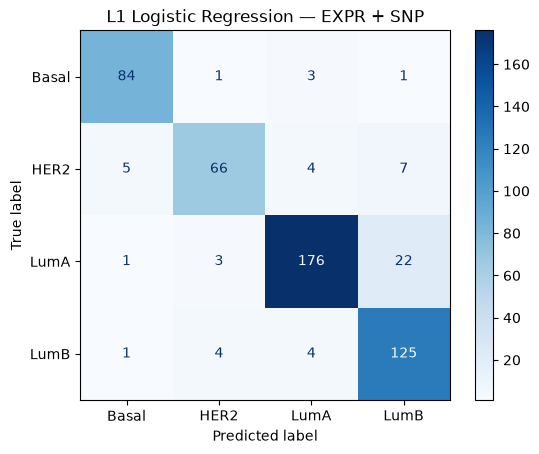

In [116]:
model_l1_expr_snp = Pipeline([
    ("preprocessor", preprocessor_expr_snp),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        solver="saga",
        l1_ratio=1,
        C=0.1,
        max_iter=5000,
        tol=0.0001,
        random_state=42
    ))
])

# Training
model_l1_expr_snp.fit(X_train_expr_snp, y_train)

# Evaluation
y_pred_l1_expr_snp = model_l1_expr_snp.predict(X_val_expr_snp)

evaluate_predictions(y_val, y_pred_l1_expr_snp)

plot_confusion(y_val, y_pred_l1_expr_snp, 'L1 Logistic Regression — EXPR + SNP')

## Multi-Omics
- HGB: **Accuracy: 0.883; Macro F1: 0.886**
- LR: **Accuracy: 0.891; Macro F1: 0.888**

In [117]:
preprocessor_all = ColumnTransformer([
    ("expr", Pipeline([
        ("selection", SelectKBest(f_classif, k=2000))
    ]), X_train_expr.columns),

    ("cnv", Pipeline([
        ("selection", SelectKBest(f_classif, k=500))
    ]), X_train_cnv.columns),

    ("snp", VarianceThreshold(), X_train_snp.columns)
])

Accuracy: 0.8836
Balanced Accuracy: 0.8876
Macro F1: 0.8869
              precision    recall  f1-score   support

       Basal       0.96      0.97      0.96        89
        HER2       0.90      0.80      0.85        82
        LumA       0.94      0.85      0.89       202
        LumB       0.77      0.93      0.84       134

    accuracy                           0.88       507
   macro avg       0.89      0.89      0.89       507
weighted avg       0.89      0.88      0.88       507



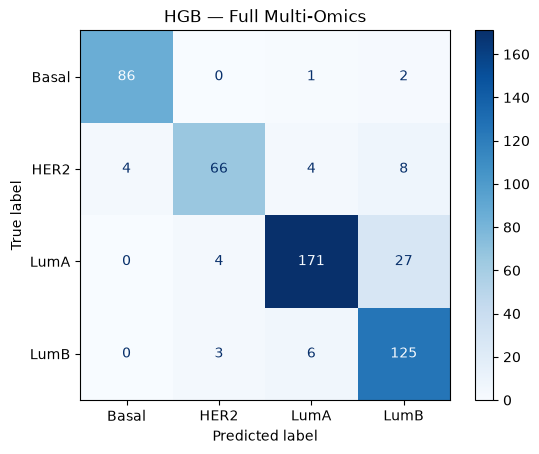

In [118]:
model_hgb_all = Pipeline([
    ("preprocessor", preprocessor_all),
    ("model", HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=15,
        random_state=42
    ))
])

# Training
model_hgb_all.fit(X_train_all, y_train)

# Evaluation
y_pred_hgb_all = model_hgb_all.predict(X_val_all)

evaluate_predictions(y_val, y_pred_hgb_all)

plot_confusion(y_val, y_pred_hgb_all, 'HGB — Full Multi-Omics')

Accuracy: 0.8915
Balanced Accuracy: 0.8894
Macro F1: 0.8888
              precision    recall  f1-score   support

       Basal       0.92      0.94      0.93        89
        HER2       0.89      0.80      0.85        82
        LumA       0.94      0.88      0.91       202
        LumB       0.81      0.93      0.87       134

    accuracy                           0.89       507
   macro avg       0.89      0.89      0.89       507
weighted avg       0.90      0.89      0.89       507



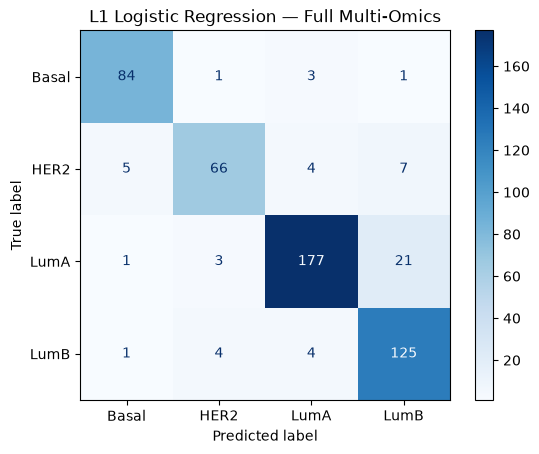

In [119]:
model_l1_all = Pipeline([
    ("preprocessor", preprocessor_all),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        solver="saga",
        l1_ratio=1,
        C=0.1,
        max_iter=5000,
        tol=0.0001,
        random_state=42
    ))
])

# Training
model_l1_all.fit(X_train_all, y_train)

# Evaluation
y_pred_l1_all = model_l1_all.predict(X_val_all)

evaluate_predictions(y_val, y_pred_l1_all)

plot_confusion(y_val, y_pred_l1_all, 'L1 Logistic Regression — Full Multi-Omics')

## CNV + SNP
- HGB: **Accuracy: 0.508; Macro F1: 0.468**
- LR: **Accuracy: 0.512; Macro F1: 0.450**

In [120]:
preprocessor_cnv_snp = ColumnTransformer([
    ("cnv", Pipeline([
        ("selection", SelectKBest(f_classif, k=500))
    ]), X_train_cnv.columns),

    ("snp", VarianceThreshold(), X_train_snp.columns)
])

Accuracy: 0.5089
Balanced Accuracy: 0.4725
Macro F1: 0.4681
              precision    recall  f1-score   support

       Basal       0.54      0.63      0.58        89
        HER2       0.40      0.23      0.29        82
        LumA       0.61      0.66      0.64       202
        LumB       0.36      0.37      0.36       134

    accuracy                           0.51       507
   macro avg       0.48      0.47      0.47       507
weighted avg       0.50      0.51      0.50       507



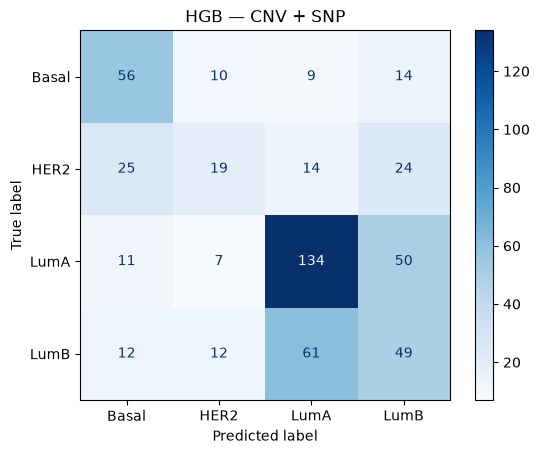

In [121]:
model_hgb_cnv_snp = Pipeline([
    ("preprocessor", preprocessor_cnv_snp),
    ("model", HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=15,
        random_state=42
    ))
])

# Training
model_hgb_cnv_snp.fit(X_train_cnv_snp, y_train)

# Evaluation
y_pred_hgb_cnv_snp = model_hgb_cnv_snp.predict(X_val_cnv_snp)

evaluate_predictions(y_val, y_pred_hgb_cnv_snp)

plot_confusion(y_val, y_pred_hgb_cnv_snp, 'HGB — CNV + SNP')

Accuracy: 0.5128
Balanced Accuracy: 0.4645
Macro F1: 0.4506
              precision    recall  f1-score   support

       Basal       0.49      0.65      0.56        89
        HER2       0.44      0.20      0.27        82
        LumA       0.64      0.74      0.69       202
        LumB       0.31      0.27      0.29       134

    accuracy                           0.51       507
   macro avg       0.47      0.46      0.45       507
weighted avg       0.49      0.51      0.49       507



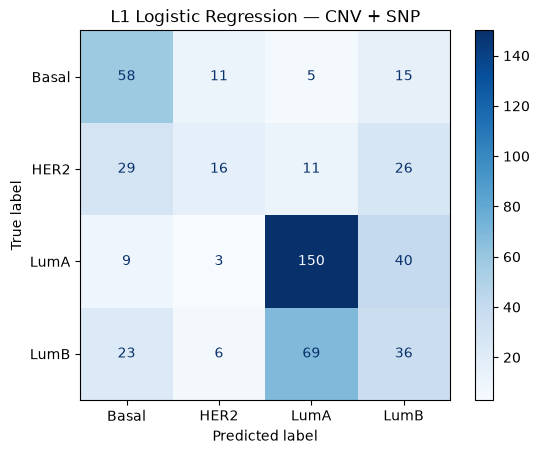

In [122]:
model_l1_cnv_snp = Pipeline([
    ("preprocessor", preprocessor_cnv_snp),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        solver="saga",
        l1_ratio=1,
        C=0.1,
        max_iter=5000,
        tol=0.0001,
        random_state=42
    ))
])

# Training
model_l1_cnv_snp.fit(X_train_cnv_snp, y_train)

# Evaluation
y_pred_l1_cnv_snp = model_l1_cnv_snp.predict(X_val_cnv_snp)

evaluate_predictions(y_val, y_pred_l1_cnv_snp)

plot_confusion(y_val, y_pred_l1_cnv_snp, 'L1 Logistic Regression — CNV + SNP')

## SVM

In [137]:
model_svm_expr = Pipeline([
    ("variance", VarianceThreshold()),
    ("selection", SelectKBest(f_classif, k=2000)),
    ("scaler", StandardScaler()),
    ("model", LinearSVC(
        C=1.0,
        max_iter=5000,
        random_state=42
    ))
])

Accuracy: 0.8185
Balanced Accuracy: 0.8134
Macro F1: 0.8126
              precision    recall  f1-score   support

       Basal       0.91      0.93      0.92        89
        HER2       0.75      0.67      0.71        82
        LumA       0.89      0.82      0.86       202
        LumB       0.71      0.83      0.76       134

    accuracy                           0.82       507
   macro avg       0.82      0.81      0.81       507
weighted avg       0.82      0.82      0.82       507



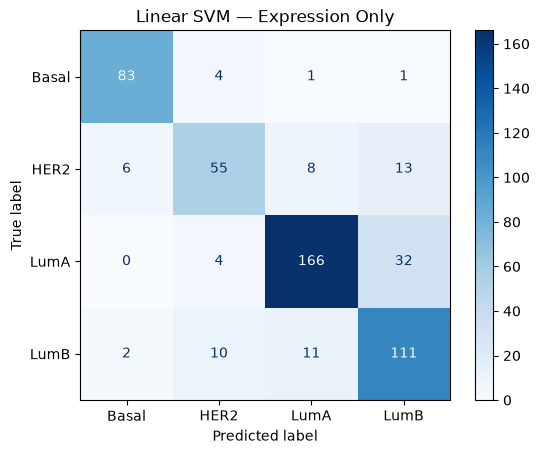

In [138]:
model_svm_expr.fit(X_train_expr, y_train)

y_pred_svm_expr = model_svm_expr.predict(X_val_expr)

evaluate_predictions(y_val, y_pred_svm_expr)

plot_confusion(y_val, y_pred_svm_expr, 'Linear SVM — Expression Only')

In [139]:
results = []

for C in [0.001, 0.01, 0.1, 1, 10]:

    model_svm_expr.set_params(model__C=C)

    model_svm_expr.fit(X_train_expr, y_train)
    y_pred = model_svm_expr.predict(X_val_expr)

    results.append({
        "C": C,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Macro F1": f1_score(y_val, y_pred, average="macro")
    })

results_svm_expr = pd.DataFrame(results)

display(results_svm_expr)

,C,Accuracy,Macro F1
0,0.001,0.856016,0.858862
1,0.010,0.830375,0.827603
2,0.100,0.820513,0.814007
3,1.000,0.818540,0.812614
4,10.000,0.818540,0.812614


In [140]:
preprocessor_svm_all = ColumnTransformer([
    ("expr", Pipeline([
        ("variance", VarianceThreshold()),
        ("selection", SelectKBest(f_classif, k=2000))
    ]), X_train_expr.columns),

    ("cnv", Pipeline([
        ("variance", VarianceThreshold()),
        ("selection", SelectKBest(f_classif, k=500))
    ]), X_train_cnv.columns),

    ("snp", VarianceThreshold(), X_train_snp.columns)
])
model_svm_all = Pipeline([
    ("preprocessor", preprocessor_svm_all),
    ("scaler", StandardScaler()),
    ("model", LinearSVC(
        C=0.001,
        max_iter=5000,
        random_state=42
    ))
])

model_svm_all.fit(X_train_all, y_train)

y_pred_svm_all = model_svm_all.predict(X_val_all)

print("Accuracy:", accuracy_score(y_val, y_pred_svm_all))
print("Macro F1:", f1_score(y_val, y_pred_svm_all, average="macro"))

Accuracy: 0.8362919132149902
Macro F1: 0.8372743958971505


In [141]:
results = []

for C in [0.001, 0.01, 0.1, 1, 10]:

    model_svm_all.set_params(model__C=C)

    model_svm_all.fit(X_train_all, y_train)
    y_pred = model_svm_all.predict(X_val_all)

    results.append({
        "C": C,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Macro F1": f1_score(y_val, y_pred, average="macro")
    })

results_svm_all = pd.DataFrame(results)

display(results_svm_all)

,C,Accuracy,Macro F1
0,0.001,0.836292,0.837274
1,0.010,0.812623,0.810965
2,0.100,0.806706,0.803520
3,1.000,0.804734,0.801234
4,10.000,0.804734,0.801234


In [142]:
model_rbf_expr = Pipeline([
    ("variance", VarianceThreshold()),
    ("selection", SelectKBest(f_classif, k=2000)),
    ("scaler", StandardScaler()),
    ("model", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

In [143]:
model_rbf_expr.fit(X_train_expr, y_train)

y_pred_rbf_expr = model_rbf_expr.predict(X_val_expr)

print("Accuracy:", accuracy_score(y_val, y_pred_rbf_expr))
print("Macro F1:", f1_score(y_val, y_pred_rbf_expr, average="macro"))

Accuracy: 0.8579881656804734
Macro F1: 0.8642254824924431


In [144]:
param_grid = {
    "C": [0.1, 1, 10],
    "gamma": ["scale", 0.0001, 0.001]
}

results = []

for params in ParameterGrid(param_grid):

    model_rbf_expr.set_params(
        model__C=params["C"],
        model__gamma=params["gamma"]
    )

    model_rbf_expr.fit(X_train_expr, y_train)

    y_pred = model_rbf_expr.predict(X_val_expr)

    results.append({
        "C": params["C"],
        "Gamma": params["gamma"],
        "Accuracy": accuracy_score(y_val, y_pred),
        "Macro F1": f1_score(y_val, y_pred, average="macro")
    })

results_rbf_expr = pd.DataFrame(results)

display(results_rbf_expr.sort_values(
    "Macro F1", ascending=False
))

,C,Gamma,Accuracy,Macro F1
6,10.0,scale,0.869822,0.870188
7,10.0,0.0001,0.869822,0.867911
4,1.0,0.0001,0.861933,0.864856
3,1.0,scale,0.857988,0.864225
5,1.0,0.001,0.852071,0.856014
8,10.0,0.001,0.856016,0.855751
0,0.1,scale,0.846154,0.845110
1,0.1,0.0001,0.806706,0.793302
2,0.1,0.001,0.741617,0.601691


In [145]:
preprocessor_rbf_all = ColumnTransformer([
    ("expr", Pipeline([
        ("variance", VarianceThreshold()),
        ("selection", SelectKBest(f_classif, k=2000))
    ]), X_train_expr.columns),

    ("cnv", Pipeline([
        ("variance", VarianceThreshold()),
        ("selection", SelectKBest(f_classif, k=500))
    ]), X_train_cnv.columns),

    ("snp", VarianceThreshold(), X_train_snp.columns)
])

model_rbf_all = Pipeline([
    ("preprocessor", preprocessor_rbf_all),
    ("scaler", StandardScaler()),
    ("model", SVC(kernel="rbf"))
])

param_grid = {
    "C": [0.1, 1, 10],
    "gamma": ["scale", 0.0001, 0.001]
}

results = []

for params in ParameterGrid(param_grid):

    model_rbf_all.set_params(
        model__C=params["C"],
        model__gamma=params["gamma"]
    )

    model_rbf_all.fit(X_train_all, y_train)
    y_pred = model_rbf_all.predict(X_val_all)

    results.append({
        "C": params["C"],
        "Gamma": params["gamma"],
        "Accuracy": accuracy_score(y_val, y_pred),
        "Macro F1": f1_score(y_val, y_pred, average="macro")
    })

results_rbf_all = pd.DataFrame(results)

display(results_rbf_all.sort_values(
    "Macro F1", ascending=False
))

,C,Gamma,Accuracy,Macro F1
7,10.0,0.0001,0.863905,0.860268
4,1.0,0.0001,0.856016,0.856930
6,10.0,scale,0.856016,0.855228
3,1.0,scale,0.838264,0.842825
0,0.1,scale,0.818540,0.806622
8,10.0,0.001,0.808679,0.804912
5,1.0,0.001,0.804734,0.804611
1,0.1,0.0001,0.790927,0.773971
2,0.1,0.001,0.402367,0.153846


In [146]:
results_k_svm = []

for k in [100, 500, 1000, 2000, 5000]:

    model_rbf_expr.set_params(
        selection__k=k,
        model__C=10,
        model__gamma="scale"
    )

    model_rbf_expr.fit(X_train_expr, y_train)
    y_pred = model_rbf_expr.predict(X_val_expr)

    results_k_svm.append({
        "K": k,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Macro F1": f1_score(y_val, y_pred, average="macro")
    })

results_k_svm = pd.DataFrame(results_k_svm)

display(results_k_svm.sort_values("Macro F1", ascending=False))

,K,Accuracy,Macro F1
2,1000,0.887574,0.886678
1,500,0.875740,0.875121
3,2000,0.869822,0.870188
4,5000,0.861933,0.862990
0,100,0.867850,0.858467


In [147]:
results_rbf_all_k = []

for gamma in ["scale", 0.0001]:

    model_rbf_all.set_params(
        preprocessor__expr__selection__k=1000,
        model__C=10,
        model__gamma=gamma
    )

    model_rbf_all.fit(X_train_all, y_train)
    y_pred = model_rbf_all.predict(X_val_all)

    results_rbf_all_k.append({
        "EXPR k": 1000,
        "CNV k": 500,
        "Gamma": gamma,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Macro F1": f1_score(y_val, y_pred, average="macro")
    })

display(pd.DataFrame(results_rbf_all_k))

,EXPR k,CNV k,Gamma,Accuracy,Macro F1
0,1000,500,scale,0.854043,0.855405
1,1000,500,0.0001,0.867850,0.867177


In [148]:
results_feature_search = []

for expr_k in [500, 1000, 2000]:
    for cnv_k in [100, 250, 500, 1000]:

        model_rbf_all.set_params(
            preprocessor__expr__selection__k=expr_k,
            preprocessor__cnv__selection__k=cnv_k,
            model__C=10,
            model__gamma=0.0001
        )

        model_rbf_all.fit(X_train_all, y_train)

        y_pred = model_rbf_all.predict(X_val_all)

        results_feature_search.append({
            "EXPR k": expr_k,
            "CNV k": cnv_k,
            "Accuracy": accuracy_score(y_val, y_pred),
            "Macro F1": f1_score(y_val, y_pred, average="macro")
        })

results_feature_search = pd.DataFrame(results_feature_search)

display(
    results_feature_search.sort_values(
        "Macro F1", ascending=False
    )
)

,EXPR k,CNV k,Accuracy,Macro F1
4,1000,100,0.881657,0.877292
5,1000,250,0.875740,0.873744
8,2000,100,0.875740,0.872987
9,2000,250,0.873767,0.870669
6,1000,500,0.867850,0.867177
7,1000,1000,0.867850,0.865626
10,2000,500,0.863905,0.860268
0,500,100,0.854043,0.854171
2,500,500,0.854043,0.852859
1,500,250,0.848126,0.848280


## Finalising Features Selections

In [149]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results_hgb_expr = []

for k in [500, 1000, 2000]:

    model = Pipeline([
        ("selection", SelectKBest(score_func=f_classif, k=k)),
        ("model", HistGradientBoostingClassifier(
            max_iter=100,
            learning_rate=0.1,
            max_leaf_nodes=15,
            random_state=42
        ))
    ])

    scores = cross_validate(
        model,
        X_train_expr,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "macro_f1": "f1_macro"
        },
        n_jobs=-1
    )

    results_hgb_expr.append({
        "EXPR k": k,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Macro F1": scores["test_macro_f1"].mean(),
        "F1 Std": scores["test_macro_f1"].std()
    })

results_hgb_expr = pd.DataFrame(results_hgb_expr)

display(
    results_hgb_expr.sort_values(
        "CV Macro F1", ascending=False
    )
)

,EXPR k,CV Accuracy,CV Macro F1,F1 Std
1,1000,0.878989,0.860557,0.035933
2,2000,0.871397,0.851695,0.042521
0,500,0.866316,0.843335,0.021055


In [150]:
results_hgb_cnv = []

for k in [100, 250, 500]:

    preprocessor = ColumnTransformer([
        ("expr", Pipeline([
            ("selection", SelectKBest(f_classif, k=1000))
        ]), X_train_expr.columns),

        ("cnv", Pipeline([
            ("selection", SelectKBest(f_classif, k=k))
        ]), X_train_cnv.columns),

        ("snp", VarianceThreshold(), X_train_snp.columns)
    ])
    
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", HistGradientBoostingClassifier(
            max_iter=100,
            learning_rate=0.1,
            max_leaf_nodes=15,
            random_state=42
        ))
    ])

    scores = cross_validate(
        model, X_train_all, y_train,
        cv=cv,
        scoring="f1_macro",
        n_jobs=2
    )

    results_hgb_cnv.append({
        "CNV k": k,
        "CV Macro F1": scores["test_score"].mean(),
        "F1 Std": scores["test_score"].std()
    })

display(pd.DataFrame(results_hgb_cnv).sort_values(
    "CV Macro F1", ascending=False
))

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,CNV k,CV Macro F1,F1 Std
2,500,0.863175,0.034738
1,250,0.859416,0.034448
0,100,0.857655,0.034894


In [151]:
cv3 = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

results_l1_cnv = []

for k in [100, 250, 500]:

    preprocessor = ColumnTransformer([
        ("expr", Pipeline([
            ("selection", SelectKBest(f_classif, k=2000))
        ]), X_train_expr.columns),

        ("cnv", Pipeline([
            ("selection", SelectKBest(f_classif, k=k))
        ]), X_train_cnv.columns),

        ("snp", VarianceThreshold(), X_train_snp.columns)
    ])
    
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            solver="saga",
            l1_ratio=1,
            C=0.1,
            max_iter=5000,
            tol=0.0001,
            random_state=42
        ))
    ])

    scores = cross_validate(
        model,
        X_train_all,
        y_train,
        cv=cv3,
        scoring="f1_macro",
        n_jobs=2
    )

    results_l1_cnv.append({
        "CNV k": k,
        "CV Macro F1": scores["test_score"].mean(),
        "F1 Std": scores["test_score"].std()
    })

results_l1_cnv = pd.DataFrame(results_l1_cnv)

display(results_l1_cnv.sort_values(
    "CV Macro F1", ascending=False
))

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,CNV k,CV Macro F1,F1 Std
0,100,0.815881,0.010063
1,250,0.815027,0.008930
2,500,0.815027,0.008930


In [152]:
results_final = []

models = {
    "HGB": (1000, HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=15,
        random_state=42
    )),
    "L1": (2000, LogisticRegression(
        solver="saga",
        l1_ratio=1,
        C=0.1,
        max_iter=5000,
        tol=0.0001,
        random_state=42
    ))
}

final_models = {}

for name, (expr_k, classifier) in models.items():

    for modality in ["EXPR", "Multi-Omics"]:

        if modality == "EXPR":
            preprocessor = Pipeline([
                ("selection", SelectKBest(f_classif, k=expr_k))
            ])
            X_tr, X_v = X_train_expr, X_val_expr

        else:
            preprocessor = ColumnTransformer([
                ("expr", Pipeline([
                    ("selection", SelectKBest(f_classif, k=expr_k))
                ]), X_train_expr.columns),

                ("cnv", Pipeline([
                    ("selection", SelectKBest(f_classif, k=500))
                ]), X_train_cnv.columns),

                ("snp", VarianceThreshold(), X_train_snp.columns)
            ])
            X_tr, X_v = X_train_all, X_val_all
        
        steps = [("preprocessor", preprocessor)]

        if name == "L1":
            steps.append(("scaler", StandardScaler()))

        steps.append(("model", classifier))

        model = Pipeline(steps)
        model.fit(X_tr, y_train)
        y_pred = model.predict(X_v)

        results_final.append({
            "Model": name,
            "Modality": modality,
            "Accuracy": accuracy_score(y_val, y_pred),
            "Balanced Accuracy": balanced_accuracy_score(y_val, y_pred),
            "Macro F1": f1_score(y_val, y_pred, average="macro")
        })

        final_models[(name, modality)] = model

results_final = pd.DataFrame(results_final)

display(results_final)

,Model,Modality,Accuracy,Balanced Accuracy,Macro F1
0,HGB,EXPR,0.885602,0.882108,0.882834
1,HGB,Multi-Omics,0.873767,0.875310,0.874201
2,L1,EXPR,0.885602,0.885657,0.884093
3,L1,Multi-Omics,0.891519,0.889443,0.888809


## No Pam50

In [153]:
pam50_genes = [
    "ACTR3B", "ANLN", "BAG1", "BCL2", "BIRC5",
    "BLVRA", "CCNB1", "CCNE1", "CDC20", "CDC6",
    "NUF2", "CDH3", "CENPF", "CEP55", "CXXC5",
    "EGFR", "ERBB2", "ESR1", "EXO1", "FGFR4",
    "FOXA1", "FOXC1", "GPR160", "GRB7", "KIF2C",
    "NDC80", "KRT14", "KRT17", "KRT5", "MAPT",
    "MDM2", "MELK", "MIA", "MKI67", "MLPH",
    "MMP11", "MYBL2", "MYC", "NAT1", "ORC6",
    "PGR", "PHGDH", "PTTG1", "RRM2", "SFRP1",
    "SLC39A6", "TMEM45B", "TYMS", "UBE2C", "UBE2T"
]

pam50_available = [
    gene for gene in pam50_genes
    if f"{gene}_EXPR" in X_train_expr.columns
]

pam50_missing = [
    gene for gene in pam50_genes
    if gene not in pam50_available
]

print("Available:", len(pam50_available))
print("Missing:", pam50_missing)

Available: 45
Missing: ['BAG1', 'GPR160', 'MIA', 'ORC6', 'TMEM45B']


In [154]:
# Remove PAM50 expression genes
pam50_expr_cols = [f"{gene}_EXPR" for gene in pam50_available]

X_train_no_pam50 = X_train_expr.drop(columns=pam50_expr_cols)
X_val_no_pam50 = X_val_expr.drop(columns=pam50_expr_cols)

# HGB pipeline
hgb_no_pam50 = Pipeline([
    ("selection", SelectKBest(f_classif, k=1000)),
    ("model", HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=15,
        random_state=42
    ))
])

hgb_no_pam50.fit(X_train_no_pam50, y_train)

y_pred = hgb_no_pam50.predict(X_val_no_pam50)

print("Accuracy:", accuracy_score(y_val, y_pred))
print("Balanced Accuracy:", balanced_accuracy_score(y_val, y_pred))
print("Macro F1:", f1_score(y_val, y_pred, average="macro"))

Accuracy: 0.8717948717948718
Balanced Accuracy: 0.8732254177263048
Macro F1: 0.8735185426243923


## PCA

In [185]:
variance = VarianceThreshold()

X_tr = variance.fit_transform(X_train_expr)
X_v = variance.transform(X_val_expr)

# Standardisation
scaler = StandardScaler()

X_tr = scaler.fit_transform(X_tr)
X_v = scaler.transform(X_v)

print("Training:", X_tr.shape)
print("Validation:", X_v.shape)

Training: (1182, 15592)
Validation: (507, 15592)


In [186]:
pca = PCA(
    n_components=300,
    svd_solver="randomized",
    random_state=42
)

X_train_pca = pca.fit_transform(X_tr)
X_val_pca = pca.transform(X_v)

print("Training:", X_train_pca.shape)
print("Validation:", X_val_pca.shape)
print("Explained variance:", pca.explained_variance_ratio_.sum())

Training: (1182, 300)
Validation: (507, 300)
Explained variance: 0.7097509611686253


### PCA only

In [187]:

models = {
    "L1": LogisticRegression(
        solver="saga",
        l1_ratio=1,
        C=0.1,
        max_iter=5000,
        tol=0.0001,
        random_state=42
    ),
    "HGB": HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=15,
        random_state=42
    )
}

results_pca = []
fitted_pca_models = {}

for n in [100, 300]:
    for name, classifier in models.items():

        X_train_n = X_train_pca[:, :n]
        X_val_n = X_val_pca[:, :n]

        classifier.fit(X_train_n, y_train)
        y_pred = classifier.predict(X_val_n)

        results_pca.append({
            "Experiment": "PCA",
            "Model": name,
            "Components": n,
            "Accuracy": accuracy_score(y_val, y_pred),
            "Balanced Accuracy": balanced_accuracy_score(y_val, y_pred),
            "Macro F1": f1_score(y_val, y_pred, average="macro")
        })

        fitted_pca_models[(name, n)] = classifier

results_pca = pd.DataFrame(results_pca)
print(results_pca)


  Experiment Model  Components  Accuracy  Balanced Accuracy  Macro F1
0        PCA    L1         100  0.879684           0.877621  0.875660
1        PCA   HGB         100  0.820513           0.804384  0.814062
2        PCA    L1         300  0.861933           0.857111  0.854939
3        PCA   HGB         300  0.781065           0.754999  0.761314


### PCA and SelectKBest

In [188]:
selector = SelectKBest(
    score_func=f_classif,
    k=2000
)

X_train_selected = selector.fit_transform(X_tr, y_train)
X_val_selected = selector.transform(X_v)

print("Training:", X_train_selected.shape)
print("Validation:", X_val_selected.shape)

Training: (1182, 2000)
Validation: (507, 2000)


In [189]:
pca_selected = PCA(
    n_components=300,
    svd_solver="randomized",
    random_state=42
)

X_train_selected_pca = pca_selected.fit_transform(X_train_selected)
X_val_selected_pca = pca_selected.transform(X_val_selected)

print("Training:", X_train_selected_pca.shape)
print("Validation:", X_val_selected_pca.shape)
print("Explained variance:", pca_selected.explained_variance_ratio_.sum())

Training: (1182, 300)
Validation: (507, 300)
Explained variance: 0.8969978065593237


In [190]:

from sklearn.base import clone

results_selected_pca = []
fitted_selected_pca_models = {}

for n in [100, 300]:
    for name, classifier in models.items():

        X_train_n = X_train_selected_pca[:, :n]
        X_val_n = X_val_selected_pca[:, :n]

        model = clone(classifier)
        model.fit(X_train_n, y_train)

        y_pred = model.predict(X_val_n)

        results_selected_pca.append({
            "Experiment": "SelectKBest + PCA",
            "Model": name,
            "Components": n,
            "Accuracy": accuracy_score(y_val, y_pred),
            "Balanced Accuracy": balanced_accuracy_score(y_val, y_pred),
            "Macro F1": f1_score(y_val, y_pred, average="macro")
        })

        fitted_selected_pca_models[(name, n)] = model

results_selected_pca = pd.DataFrame(results_selected_pca)
print(results_selected_pca)


          Experiment Model  Components  Accuracy  Balanced Accuracy  Macro F1
0  SelectKBest + PCA    L1         100  0.881657           0.878931  0.878379
1  SelectKBest + PCA   HGB         100  0.826430           0.816040  0.818641
2  SelectKBest + PCA    L1         300  0.873767           0.866108  0.867270
3  SelectKBest + PCA   HGB         300  0.830375           0.823008  0.833273


In [191]:

results_dim_reduction = pd.concat(
    [results_pca, results_selected_pca],
    ignore_index=True
)

results_dim_reduction = results_dim_reduction.sort_values(
    "Macro F1",
    ascending=False
)

print(results_dim_reduction.to_string(index=False))

       Experiment Model  Components  Accuracy  Balanced Accuracy  Macro F1
SelectKBest + PCA    L1         100  0.881657           0.878931  0.878379
              PCA    L1         100  0.879684           0.877621  0.875660
SelectKBest + PCA    L1         300  0.873767           0.866108  0.867270
              PCA    L1         300  0.861933           0.857111  0.854939
SelectKBest + PCA   HGB         300  0.830375           0.823008  0.833273
SelectKBest + PCA   HGB         100  0.826430           0.816040  0.818641
              PCA   HGB         100  0.820513           0.804384  0.814062
              PCA   HGB         300  0.781065           0.754999  0.761314


# Stage 6 — External validation on TCGA-BRCA

## Stacking

In [ ]:
X_metabric = pd.concat([X_train_all, X_val_all], axis=0)
y_metabric = pd.concat([y_train, y_val], axis=0)

print("METABRIC:", X_metabric.shape)
print("TCGA:", X_test_all.shape)

METABRIC: (1689, 46776)
TCGA: (631, 46776)


In [221]:
from sklearn.ensemble import StackingClassifier, VotingClassifier

stacking = StackingClassifier(
    estimators=[
        ("hgb", hgb_multi),
        ("l1", l1_multi)
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    stack_method="predict_proba",
    cv=3
)

soft_voting = VotingClassifier(
    estimators=[
        ("hgb", hgb_multi),
        ("l1", l1_multi)
    ],
    voting="soft"
)

In [222]:
models = {
    "Soft Voting": soft_voting,
    "Stacking": stacking
}

results = []

for name, model in models.items():
    model.fit(X_train_all, y_train)
    pred = model.predict(X_val_all)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_val, pred),
        "Macro F1": f1_score(y_val, pred, average="macro")
    })

display(pd.DataFrame(results).round(4))

,Model,Accuracy,Balanced Accuracy,Macro F1
0,Soft Voting,0.8895,0.8913,0.8905
1,Stacking,0.8876,0.8864,0.8836


In [223]:
X_metabric = pd.concat([X_train_all, X_val_all])
y_metabric = pd.concat([y_train, y_val])

results_tcga = []

for name, model in models.items():
    model.fit(X_metabric, y_metabric)
    pred = model.predict(X_test_all)

    results_tcga.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro")
    })

display(pd.DataFrame(results_tcga).round(4))

,Model,Accuracy,Balanced Accuracy,Macro F1
0,Soft Voting,0.8796,0.8523,0.8462
1,Stacking,0.8764,0.8532,0.8460


## Findings

In [224]:
# Get fitted models from stacking
hgb_final = stacking.named_estimators_["hgb"]
l1_final = stacking.named_estimators_["l1"]

# L1 feature importance
features = l1_final.named_steps["preprocessor"].get_feature_names_out()
coef = l1_final.named_steps["model"].coef_

l1_importance = pd.DataFrame({
    "Feature": features,
    "Importance": np.abs(coef).mean(axis=0),
    "Nonzero": (coef != 0).any(axis=0)
})

l1_importance["Modality"] = l1_importance["Feature"].str.split("__").str[0].str.upper()

# Top 20 features
print("L1 Logistic Regression — Top 20 Features")
display(
    l1_importance[l1_importance["Nonzero"]]
    .nlargest(20, "Importance")
)

# Modality summary
l1_modality = l1_importance.groupby("Modality").agg(
    Total_Features=("Feature", "count"),
    Nonzero_Features=("Nonzero", "sum"),
    Total_Importance=("Importance", "sum")
)

l1_modality["Importance_Percent"] = (
    l1_modality["Total_Importance"] / l1_modality["Total_Importance"].sum() * 100
)

print("L1 Logistic Regression — Modality Importance")
display(l1_modality.round(2))

L1 Logistic Regression — Top 20 Features


,Feature,Importance,Nonzero,Modality
923,expr__KRT14_EXPR,0.224158,True,EXPR
925,expr__KRT17_EXPR,0.164433,True,EXPR
564,expr__ESR1_EXPR,0.158855,True,EXPR
1631,expr__SLC39A6_EXPR,0.145853,True,EXPR
559,expr__ERBB2_EXPR,0.137453,True,EXPR
392,expr__COL17A1_EXPR,0.134510,True,EXPR
1576,expr__SFRP1_EXPR,0.118450,True,EXPR
314,expr__CDCA3_EXPR,0.109407,True,EXPR
372,expr__CKAP2L_EXPR,0.108878,True,EXPR
172,expr__BIRC5_EXPR,0.105017,True,EXPR


L1 Logistic Regression — Modality Importance


,Total_Features,Nonzero_Features,Total_Importance,Importance_Percent
Modality,,,,
CNV,500,7,0.06,0.93
EXPR,2000,259,6.21,92.11
SNP,163,40,0.47,6.96


In [225]:
features = hgb_final.named_steps["preprocessor"].get_feature_names_out()

# Count how often each feature is used in tree splits
split_features = [
    i
    for trees in hgb_final.named_steps["model"]._predictors
    for tree in trees
    for i in tree.nodes["feature_idx"][tree.nodes["is_leaf"] == 0]
]

counts = Counter(split_features)

hgb_importance = pd.DataFrame({
    "Feature": [features[i] for i in counts],
    "Split_Count": list(counts.values())
})

hgb_importance["Modality"] = hgb_importance["Feature"].str.split("__").str[0].str.upper()

# Top 20 features
print("HistGradientBoosting — Top 20 Features")
display(hgb_importance.nlargest(20, "Split_Count"))

# Modality summary
hgb_modality = hgb_importance.groupby("Modality").agg(
    Features_Used=("Feature", "count"),
    Total_Splits=("Split_Count", "sum")
)

hgb_modality["Split_Percent"] = (
    hgb_modality["Total_Splits"] / hgb_modality["Total_Splits"].sum() * 100
)

print("HistGradientBoosting — Modality Importance")
display(hgb_modality.round(2))

HistGradientBoosting — Top 20 Features


,Feature,Split_Count,Modality
26,expr__ESR1_EXPR,93,EXPR
12,expr__ERBB2_EXPR,91,EXPR
34,expr__KRT14_EXPR,89,EXPR
27,expr__SFRP1_EXPR,78,EXPR
20,expr__KRT5_EXPR,74,EXPR
16,expr__SLC39A6_EXPR,71,EXPR
48,expr__FOXC1_EXPR,70,EXPR
13,expr__FGFR4_EXPR,59,EXPR
85,expr__KRT17_EXPR,55,EXPR
67,expr__MAPT_EXPR,44,EXPR


HistGradientBoosting — Modality Importance


,Features_Used,Total_Splits,Split_Percent
Modality,,,
CNV,1,2,0.04
EXPR,910,5506,99.89
SNP,1,4,0.07


In [226]:
import joblib

joblib.dump(stacking, "breast_cancer_stacking.pkl")
joblib.dump(soft_voting, "breast_cancer_soft_voting.pkl")

['breast_cancer_soft_voting.pkl']

# DEMO Data Set

In [ ]:
demo_df = X_test.head(5)
demo_df.to_csv("demo_test.csv", index=False)
print(demo_df.shape)

(5, 46776)


In [9]:
y_test_demo = y_test.head(5)
y_test_demo 

0    3
1    3
2    2
3    2
4    2
Name: Pam50Subtype, dtype: int64